<div align="center"> 

---



# **Cerebellum Mega Analysis**


<img src="https://static.wixstatic.com/media/da4857_5f6dbdb6bbd84328b1e31c7f2dafb673~mv2.png/v1/fill/w_224,h_226,al_c,q_85,usm_0.66_1.00_0.01,enc_auto/enigma_addiction-300x249.png" alt="image" style="width:300px;"/>


 </img>
</div>


---
# <u> **Project Description:**</u>

The aim of this study is to perform a multi-site mega/meta analysis to asses the effects of substance use on volumetric changes in cerebellar regions (and far beyond). 

## **Hypothesis to test**

**Variables to consider:** 
  - Age
  - Sex
  - Polysubstance use : Smoke and alcohol
  
  
  **Analysis:**
   1. Volume comparisons between-groups of:
   - cerebellum regions

2. Main effects: Acapulco atlas
- Cerebellar volume ~ any drug
- Cerebellar volume ~ drug type

3. Interaction effects: Cerebellum volume
- group * sex
- group + age + sex

4. Partial Least Square: Cerebral - cerebellar association
- MDTB atlas

---

In [1]:
addTaskCallback(function(...) {set.seed(42);TRUE})
options(warn=-1) # to turn off warnings
#options(warn=0) # to turn on warnings
options(repr.plot.width=10, repr.plot.height=6) # to resize plots

1 
1

In [2]:
setwd("/mnt/g/Other computers/My Laptop/PhD/Psilantro/Enigma_cerebellum/Enigma_Cerebellum/")

## Load Packages

In [3]:
# Load required packages  
  pacman::p_load(tidyverse,devtools,readxl,ggbeeswarm,gtExtras,gt,webshot,webshot2,VIM,
                ggpubr,cowplot,gtsummary,ff,ggthemes,scales,mice,vtreat,sjmisc,SmartEDA,boot,MKinfer,
                ggcorrplot,olsrr,lme4,rstatix,janitor,coin,rcartocolor,ggdist,gghalves,ggnewscale,patchwork,
                lsr,tidyr,reshape2,broom,irr,ggpubr,caret,tidymodels,png,grid,gridExtra,ggseg)


## Set settings for plotting

In [4]:
theme_output  <- theme(text = element_text(family = "Times New Roman"),
                        axis.text.x = element_text(size = 20),
                        axis.text.y = element_text(size = 20),
                        axis.title.x = element_text(size = 22),
                        axis.title.y = element_text(size = 22),
                        legend.text = element_text(size = 22), 
                        legend.title = element_text(size = 24),
                        title = element_text(size = 20),
                        plot.title = element_text(face = "bold"))

pal_sex <- c(alpha("#8E5A9C",1),alpha("#2879BC",1))
pal_user <- c("HC" = alpha("#757575",1), "User" = alpha("#059DC7",1))
pal_substances <- c("HC" = alpha("#757575",1), "ALC" = alpha("#C93F4D",1), 
    "ATS" = alpha("#EB8F33",1), "CANN" = alpha("#0B8755",1), 
    "COC" = alpha("#3A5589",1), "NIC" = alpha("#764EA1",1))

common_gradient_scale <- scale_fill_gradient2(
    low = "#19799F",
    mid = "#ffffff",
    high = "#DE5916",
    midpoint = 0,
    na.value = "#E7E7E7"
)

common_gradient_scale2 <- scale_fill_gradient2(
    low = "#505da0",
    mid = "#ffffff",
    high = "#cf203e",
    midpoint = 0,
    na.value = "#E7E7E7"
)

# Define the color gradient
create_color_gradient <- function(min_val, max_val, palette = c("#19799F", "#ffffff", "#DE5916")) {
  scales::col_numeric(
    palette = palette,
    domain = c(min_val, max_val)
  )
}

# Define the color gradient
create_color_gradient2 <- function(min_val, max_val, palette = c("#505da0", "#ffffff", "#cf203e")) {
  scales::col_numeric(
    palette = palette,
    domain = c(min_val, max_val)
  )
}

In [5]:
`%notin%` <- Negate(`%in%`)

## Load files

In [6]:
load("Data/RData/Volumes_Cerebellum.RData")
load("Statistics/Linear_models/Acapulco/Acapulco_volumes_statistics.RData")
load("Statistics/Linear_models/Acapulco/Acapulco_full_folds_matchit_comparison.RData")
load("Statistics/Linear_models/MDTB/MDTB_volumes_statistics.RData")
load("Statistics/Linear_models/MDTB/MDTB_full_folds_matchit_comparison.RData")
load("Data/RData/Plots/Acapulco_MDTB_DK_Plots.RData")
load("Data/RData/Acapulco_PLS_figures.RData")
load("Data/RData/MDTB_PLS_figures.RData")
load("Statistics/Sanity_check/Acapulco/Acapulco_sanity_check_statistics.RData")
load("Statistics/Sanity_check/MDTB/MDTB_sanity_check_statistics.RData")

## **1. Set all the data**

### **1.1 Checking data**

In [7]:
substances_names  <- unique(Acapulco_volumes$Substance)[unique(Acapulco_volumes$Substance) !="HC"] %>% as.vector()
Acapulco_volumes <- Acapulco_volumes# %>% rename("Right.IV" = "Rigt.IV") 

In [8]:
p_values_Acapulco_user_vs_control_2plot <- p_values_Acapulco_user_vs_control %>% 
    mutate(region = factor(region, levels = c(
        grep("Left", unique(region), value = TRUE),
        grep("Rig", unique(region), value = TRUE),
        grep("Vermis", unique(region), value = TRUE),
        grep("GM", unique(region), value = TRUE),
        grep("Corpus", unique(region), value = TRUE),
        grep("Total", unique(region), value = TRUE) ))) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>%
    arrange(region) 

Acapulco_cerebellar_regions_names <- Acapulco_volumes %>%
    select(contains(c(".","_Vol"))) %>% colnames()
Acapulco_cerebellar_regions_names_2plot <- tibble(region = Acapulco_cerebellar_regions_names) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region)) %>% unlist()

## **2. Supplementaries figures**

### **Figure S1**

In [10]:
Volumes_Cerebellum_Acapulco_summary <- Volumes_Cerebellum_Acapulco_Harmonized %>% 
                    mutate(Substance = case_when(Control != 0 ~ Substance, Control == 0 ~ "HC"),
                      Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC")) ) %>% 
                    filter(!is.na(Substance)) %>% group_by(Substance) %>% 
                      summarise(n = n()) 

Volumes_Cerebellum_Acapulco_summary$ymax <- cumsum(Volumes_Cerebellum_Acapulco_summary$n)
Volumes_Cerebellum_Acapulco_summary$ymin <- c(0, head(Volumes_Cerebellum_Acapulco_summary$ymax, n=-1))
Volumes_Cerebellum_Acapulco_summary$labelPosition <- (Volumes_Cerebellum_Acapulco_summary$ymax + Volumes_Cerebellum_Acapulco_summary$ymin)

Volumes_Cerebellum_Acapulco_summary$ymax <- cumsum(Volumes_Cerebellum_Acapulco_summary$n)
Volumes_Cerebellum_Acapulco_summary$ymin <- c(0, head(Volumes_Cerebellum_Acapulco_summary$ymax, n=-1))
Volumes_Cerebellum_Acapulco_summary$labelPosition <- (Volumes_Cerebellum_Acapulco_summary$ymax + Volumes_Cerebellum_Acapulco_summary$ymin) / 2

#### Plot elements

In [11]:
Figure_S1_a <- wrap_elements(
      Excluded_plot +
            geom_text(x = 1.4, aes(y = labelPosition, label = n), size = 9) +
            theme(
                  text = element_text(size = 20),
                  legend.position = "bottom",
                  legend.box = "vertical",
                  legend.text = element_text(size = 25)
            ) +
            guides(
                  fill = guide_legend(order = 2),
                  color = guide_legend(order = 2)
            )
)

In [12]:
Figure_S1_b <- ggplot(Volumes_Cerebellum_Acapulco_summary) +
  geom_rect(
    aes(ymin = cumsum(n) - n, ymax = cumsum(n), 
        xmin = 0, xmax = 1, fill = Substance),
  ) +
  scale_fill_manual(values = alpha(pal_substances, 1)) +
  new_scale_fill() +
  geom_rect(
    aes(ymin = cumsum(n) - n + 10, ymax = cumsum(n)-10, 
        xmin = 1.02, xmax = 1.04)) +
  scale_fill_manual(values = alpha(c("#069fe4","#ea5858"),1)) + 
  theme_void() + coord_polar(theta = "y") +
  theme(text = element_text(size = 20),
        legend.position = "bottom", 
        legend.title = element_blank(),
        legend.text = element_text(size = 25)
  ) +
  geom_text( x=1.2, aes(y=labelPosition, label=n), size=13, color = "black") +
  guides(fill = guide_legend(nrow = 1, byrow = TRUE))  

In [13]:
Figure_S1_c <- bind_rows(Acapulco_volumes_raw_folds_list, .id = "fold") %>% group_by(fold, Substance) %>%
    summarize(count = n())  %>%
    ggplot(aes(x = count, color = Substance, fill = Substance)) +
        geom_histogram(bins = 50) +
        theme_ggdist() +
        facet_wrap(~Substance, scales = "free") +
        labs(x = "Number of observations", y = "Density") +
        scale_color_manual(values = pal_substances) +
        scale_fill_manual(values = pal_substances) +
        theme_output +
        theme(strip.text = element_text(size = 18),
            axis.text.x = element_text(angle = 30, hjust = 1, vjust = 1, size = 25),
            axis.title.x = element_text(size = 30),
            axis.title.y = element_text(size = 30),
        legend.position = "none") 

`summarise()` has grouped output by 'fold'. You can override using the
`.groups` argument.


In [14]:
# Count subjects per Database x Substance (including HC)
subjects_per_db_substance <- Volumes_Cerebellum_Acapulco_raw %>%
    mutate(Substance = if_else(Control == 0, "HC", as.character(Substance))) %>%
    filter(!is.na(Substance)) %>%
    mutate(Substance = factor(Substance, levels = c("ALC","ATS","CANN","COC","NIC","OPI","HC"))) %>%
    group_by(Database, Substance) %>%
    summarise(n_subjects = dplyr::n_distinct(ID_MRI), .groups = "drop") %>%
    arrange(Database, Substance)

Figure_S1_d <- subjects_per_db_substance %>%
  ggplot(aes(x = n_subjects,
             y = forcats::fct_reorder(Database, n_subjects, .fun = sum, .desc = TRUE),
             fill = Substance)) +
  geom_col(width = 0.7) +
  scale_fill_manual(values = pal_substances, drop = FALSE) +
  scale_x_continuous(expand = c(0, 0)) +
  labs(title = "Subjects per Database by Substance",
       x = "Number of subjects",
       y = "Database",
       fill = NULL) +
  theme_output +
  theme(
    legend.position = "bottom",
    legend.title = element_blank(),
    legend.text = element_text(size = 30, margin = margin(l = 6, r = 15)),
    legend.key.width = unit(1.5, "lines"),
    legend.spacing.x = unit(1.2, "cm"),
    panel.grid.major.y = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1, size = 25),
    axis.text.y = element_text(size = 20),
    axis.title.x = element_text(size = 30),
    axis.title.y = element_text(size = 30)
  ) +
  guides(fill = guide_legend(nrow = 1, byrow = TRUE)) +
  coord_flip()

#### Wrap them

In [15]:
options(repr.plot.width=30, repr.plot.height=20) # to resize plots
Figure_S1_abc <- wrap_elements(Figure_S1_a+Figure_S1_b+Figure_S1_c +
    plot_layout(ncol = 3, widths = c(0.8,1,1.2)) +
    plot_annotation(tag_levels = "a", tag_suffix = ")") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 40)))

Figure_S1 <- wrap_elements(
    Figure_S1_abc + (Figure_S1_d + labs(tag = "d)")) +
        plot_layout(ncol = 1, heights = c(1.5,0.6)) &
        theme(plot.title = element_text(hjust = 0.5, size = 22),
                    plot.subtitle = element_text(hjust = 0.5, size = 18),
                    plot.tag = element_text(face = "bold", family = "Times New Roman", size = 40)))

### **Figure S2**

#### Acapulco

In [16]:
library(patchwork)

Acapulco_folds_distribution_plots <- map(Acapulco_cerebellar_regions_names_2plot, function(region) {
  map(substances_names, function(substance) {
    p_values_Acapulco_folds_substance_vs_control %>% 
      filter(region == !!region) %>%
      filter(Substance == substance) %>%
      ggplot(aes( x = p_adj, fill = Substance )) +
      stat_slab(#subguide = subguide_inside(position = "left"),
        color = "gray15", aes(fill = after_stat(x < 0.05))
      ) +
      stat_spike(aes(linetype = after_stat(at)), at = c("median" = median)) +
      scale_fill_brewer(na.value = "gray95") +
      scale_thickness_shared() +
      scale_x_continuous(breaks = seq(0, 1, by = 0.1)) +
      scale_fill_manual(values = c("gray85", "gray85", pal_substances[substance][[1]])) +
      scale_y_continuous(breaks = seq(0.5, 1, by = 0.5), labels = percent_format()) +
      xlim(0, 1) + 
      theme_ggdist() +
      theme_output + 
      labs(x = "q-value", y = substance) +
      theme(axis.title.y = element_text(size = 16, face = "bold"),
            legend.position = "none",
            legend.title = element_blank()) 
  }) %>% set_names(substances_names) 
}) %>% set_names(Acapulco_cerebellar_regions_names_2plot)

Acapulco_substances_folds_distribution_plots <- map(Acapulco_folds_distribution_plots, function(plot_list) {
  plot_list$ALC + plot_list$ATS + plot_list$CANN + plot_list$COC + plot_list$NIC + 
    plot_layout(ncol = 1, nrow = 5, axes = "collect") 
}) %>% set_names(Acapulco_cerebellar_regions_names_2plot)


Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace 

In [17]:
Acapulco_substances_folds_distribution_plots_GSTV <- ggarrange(plotlist = map(
    c("Corpus.Medullare", "GM_Vol", "Total_Cerebel_Vol",
      Acapulco_cerebellar_regions_names_2plot %>%
      keep(~ str_starts(.x, "Vermis"))), 
    ~ Acapulco_substances_folds_distribution_plots[[.x]] + 
        plot_annotation(subtitle = .x) & 
        theme(plot.subtitle = element_text(size = 22, hjust = 0.6))), ncol = 3, 
    nrow = 3)

Acapulco_substances_folds_distribution_plots_left <- ggarrange(plotlist = map(
    c(Acapulco_cerebellar_regions_names_2plot %>%
      keep(~ str_starts(.x, "Left"))), 
    ~ Acapulco_substances_folds_distribution_plots[[.x]] + 
        plot_annotation(subtitle = .x) & 
        theme(plot.subtitle = element_text(size = 22, hjust = 0.6))), ncol = 3, 
    nrow = 4)

Acapulco_substances_folds_distribution_plots_right <- ggarrange(plotlist = map(
    c(Acapulco_cerebellar_regions_names_2plot %>%
      keep(~ str_starts(.x, "Right"))), 
    ~ Acapulco_substances_folds_distribution_plots[[.x]] + 
        plot_annotation(subtitle = .x) & 
        theme(plot.subtitle = element_text(size = 22, hjust = 0.6))), ncol = 3, 
    nrow = 4)

In [18]:
Acapulco_substances_folds_distribution_plots_all <- list(
    Acapulco_substances_folds_distribution_plots_GSTV,
    Acapulco_substances_folds_distribution_plots_left,
    Acapulco_substances_folds_distribution_plots_right)

names(Acapulco_substances_folds_distribution_plots_all) <- c(
    "Acapulco_substances_folds_distribution_plots_GSTV",
    "Acapulco_substances_folds_distribution_plots_left",
    "Acapulco_substances_folds_distribution_plots_right")

#### MDTB

In [19]:
MDTB_cerebellar_regions_names <- MDTB_volumes %>%
    select("region_1":"region_10") %>% colnames()

MDTB_folds_distribution_plots <- map(MDTB_cerebellar_regions_names, function(region) {
  map(substances_names, function(substance) {
    p_values_MDTB_folds_substance_vs_control %>% 
      filter(region == !!region) %>%
      filter(Substance == substance) %>%
      ggplot(aes( x = p_adj, fill = Substance )) +
      stat_slab(#subguide = subguide_inside(position = "left"),
        color = "gray15", aes(fill = after_stat(x < 0.05))
      ) +
      stat_spike(aes(linetype = after_stat(at)), at = c("Mode" = Mode, "median" = median)) +
      scale_fill_brewer(na.value = "gray95") +
      scale_thickness_shared() +
      scale_x_continuous(breaks = seq(0, 1, by = 0.1)) +
      scale_fill_manual(values = c("gray85", "gray85", pal_substances[substance][[1]])) +
      scale_y_continuous(breaks = seq(0.5, 1, by = 0.5), labels = percent_format()) +
      xlim(0, 1) + 
      theme_ggdist() +
      theme_output + 
      labs(x = "q-value", y = substance) +
      theme(axis.title.y = element_text(size = 16, face = "bold"),
            legend.position = "none",
            legend.title = element_blank()) 
  }) %>% set_names(substances_names) 
}) %>% set_names(MDTB_cerebellar_regions_names)

MDTB_substances_folds_distribution_plots <- map(MDTB_folds_distribution_plots, function(plot_list) {
  plot_list$ALC + plot_list$ATS + plot_list$CANN + plot_list$COC + plot_list$NIC + 
    plot_layout(ncol = 1, nrow = 5, axes = "collect") 
}) %>% set_names(MDTB_cerebellar_regions_names)


Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace 

In [20]:
MDTB_substances_folds_distribution_plots_1_6 <- ggarrange(plotlist = map(
    c("region_1", "region_2", "region_3", "region_4", "region_5", "region_6"), 
    ~ MDTB_substances_folds_distribution_plots[[.x]] + 
        plot_annotation(subtitle = .x) & 
        theme(plot.subtitle = element_text(size = 22, hjust = 0.6))), ncol = 3, 
    nrow = 2)

MDTB_substances_folds_distribution_plots_7_10 <- ggarrange(plotlist = map(
    c("region_7", "region_8", "region_9", "region_10"), 
    ~ MDTB_substances_folds_distribution_plots[[.x]] + 
        plot_annotation(subtitle = .x) & 
        theme(plot.subtitle = element_text(size = 22, hjust = 0.6))), ncol = 2, 
    nrow = 2)

In [21]:
MDTB_substances_folds_distribution_plots_all <- list(
    MDTB_substances_folds_distribution_plots_1_6,
    MDTB_substances_folds_distribution_plots_7_10)

names(MDTB_substances_folds_distribution_plots_all) <- c(
    "MDTB_substances_folds_distribution_plots_1_6",
    "MDTB_substances_folds_distribution_plots_7_10")

### **Figure S3**

#### Plot elements

In [22]:
Acapulco_cerebellar_allrois_names <- Acapulco_volumes %>%
    select(-c(Substance,group,ID_MRI,Database,Total_Cerebel_Vol, GM_Vol, Corpus.Medullare)) %>% colnames()

    # boxplots 
    plots_Acapulco_user_allrois <- map(Acapulco_cerebellar_allrois_names, function(roi) {

        cuca = Acapulco_user_merged_full_folds_matchit %>%
            filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>% 
            filter(p.adj_matchit < 0.05,
                   !is.na(p.adj_CC), p.adj_CC < 0.05,
                   !is.na(p.adj_AI), p.adj_AI < 0.05) %>% 
            select(region, p.value, p.adj_matchit) %>%
            add_column(group = "User") %>%
            add_column(group1 = "HC") %>%
            mutate(group2 = "User",
                    .y. = roi) %>%
            add_significance("p.adj_matchit") %>% filter(region == roi)

        if (nrow(cuca) > 0) {
            Acapulco_volumes %>% 
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC")),
                group = factor(group, levels = c("HC","User"))) %>%
                filter(!is_outlier(!!sym(roi), 2.5)) %>%
                ggplot(aes(x = group, y = !!sym(roi), fill = group)) + 
                stat_halfeye(
                    adjust = .8, width = .7, fill = "grey85",
                    interval_colour = NA, 
                    position = position_nudge(x = .01),
                    aes(thickness = stat(f*n))) +
                geom_boxplot(outlier.colour = NA, 
                                notch = TRUE, 
                                alpha = 0.8, 
                                size = 1, 
                                width = 0.4, aes(fill = group)) +
                scale_fill_manual(values = pal_user) +
                scale_color_manual(values = pal_user) +
                labs(title = paste(roi),
                    x = "", y = "Volume") +
                theme_ggdist() +
                theme_output +
                theme(strip.text = element_text(size = 16),
                        title = element_text(hjust = 0.5),
                        strip.background = element_rect(fill = "white"),
                        legend.position = "none") + 
            stat_pvalue_manual(cuca, label = "p.adj_matchit.signif",
                y.position = Acapulco_volumes %>%
                    filter(!is_outlier(!!sym(roi), 2.5)) %>% 
                    select(roi) %>% 
                    max(), step.increase = 0.06,
                tip.length = 0.01, size = 7) 
        } else {
            Acapulco_volumes %>%
                filter(!is_outlier(!!sym(roi), 2.5)) %>% 
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC")),
                group = factor(group, levels = c("HC","User"))) %>%
                ggplot(aes(x = group, y = !!sym(roi), fill = group)) + 
                stat_halfeye(
                    adjust = .8, width = .7, fill = "grey85",
                    interval_colour = NA, 
                    position = position_nudge(x = .01),
                    aes(thickness = stat(f*n))) +
                geom_boxplot(outlier.colour = NA, 
                                notch = TRUE, 
                                alpha = 0.8, 
                                size = 1, 
                                width = 0.4, aes(fill = group)) +
                scale_fill_manual(values = pal_user) +
                scale_color_manual(values = pal_user) +
                labs(title = paste(roi),
                    x = "", y = "Volume") +
                theme_ggdist() +
                theme_output +
                theme(strip.text = element_text(size = 16),
                        title = element_text(hjust = 0.5),
                        strip.background = element_rect(fill = "white"),
                        legend.position = "none")
        }
    }) %>% set_names(Acapulco_cerebellar_allrois_names)

#### Plot

In [23]:
Figure_S3_first <- plots_Acapulco_user_allrois[1:9] %>% wrap_plots() +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect") 

Figure_S3_second <- plots_Acapulco_user_allrois[10:18] %>% wrap_plots() +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect") 

Figure_S3_third <- plots_Acapulco_user_allrois[19:27] %>% wrap_plots() +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect") 

Figure_S3 <- list(Figure_S3_first,Figure_S3_second,Figure_S3_third)

### **Figure S4**

#### Plot elements

In [24]:
MDTB_cerebellar_names <- MDTB_volumes %>% select(contains("region_")) %>% colnames()

    # boxplots 
    plots_MDTB_user <- map(MDTB_cerebellar_names, function(roi) {

        cuca = MDTB_user_merged_full_folds_matchit %>% 
            filter(p.adj_matchit < 0.05,
                   !is.na(p.adj_CC), p.adj_CC < 0.05,
                   !is.na(p.adj_AI), p.adj_AI < 0.05) %>% 
            select(region, p.value, p.adj_matchit) %>%
            add_column(group = "User") %>%
            add_column(group1 = "HC") %>%
            mutate(group2 = "User",
                    .y. = roi) %>%
            add_significance("p.adj_matchit") %>% filter(region == roi)
            
            if (nrow(cuca) > 0) {
                MDTB_volumes %>% 
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC")),
                group = factor(group, levels = c("HC","User"))) %>%
                filter(!is_outlier(!!sym(roi), 2.5)) %>%
                ggplot(aes(x = group, y = !!sym(roi), fill = group)) + 
                stat_halfeye(
                    adjust = .8, width = .7, fill = "grey85",
                    interval_colour = NA, 
                    position = position_nudge(x = .01),
                    aes(thickness = stat(f*n))) +
                geom_boxplot(outlier.colour = NA, 
                        notch = TRUE, 
                        alpha = 0.8, 
                        size = 1, 
                        width = 0.4, aes(fill = group)) +
                scale_fill_manual(values = pal_user) +
                scale_color_manual(values = pal_user) +
                labs(title = paste(roi),
                    x = "", y = "Volume") +
                theme_ggdist() +
                theme_output +
                theme(strip.text = element_text(size = 16),
                    title = element_text(hjust = 0.5),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none") + 
                stat_pvalue_manual(cuca, label = "p_adj_matchit.signif",
                y.position = MDTB_volumes %>%
                    filter(!is_outlier(!!sym(roi), 2.5)) %>% 
                    select(roi) %>% 
                    max() + 0.005, step.increase = 0.08,
                tip.length = 0.01, size = 7) 
            } else {
                MDTB_volumes %>%
                filter(!is_outlier(!!sym(roi), 2.5)) %>%
                ggplot(aes(x = group, y = !!sym(roi), fill = group)) + 
                stat_halfeye(
                    adjust = .8, width = .7, fill = "grey85",
                    interval_colour = NA, 
                    position = position_nudge(x = .01),
                    aes(thickness = stat(f*n))) +
                geom_boxplot(outlier.colour = NA, 
                        notch = TRUE, 
                        alpha = 0.8, 
                        size = 1, 
                        width = 0.4, aes(fill = group)) +
                scale_fill_manual(values = pal_user) +
                scale_color_manual(values = pal_user) +
                labs(title = paste(roi),
                    x = "", y = "Volume") +
                theme_ggdist() +
                theme_output +
                theme(strip.text = element_text(size = 16),
                    title = element_text(hjust = 0.5),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none") 
            }
    }) %>% set_names(MDTB_cerebellar_names)

#### Plot

In [25]:
Figure_S4_first <- plots_MDTB_user[1:6] %>% wrap_plots() +
    plot_layout(ncol = 3, nrow = 2,
    guides = "collect", axis_titles = "collect")

Figure_S4_second <- plots_MDTB_user[7:10] %>% wrap_plots() +
    plot_layout(ncol = 2, nrow = 2,
    guides = "collect", axis_titles = "collect")

Figure_S4 <- list(Figure_S4_first,Figure_S4_second)

### **Figure S5**

#### Plot elements

In [21]:
Acapulco_cerebellar_allrois <- Acapulco_volumes %>%
    select(-c(Substance,group,ID_MRI,Database,Total_Cerebel_Vol,GM_Vol,Corpus.Medullare)) %>% colnames()

    # boxplots 
    plots_Acapulco_allrois <- map(Acapulco_cerebellar_allrois, function(roi) {

        cuca = Acapulco_substance_merged_full_folds_matchit %>% 
            filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>% 
            filter(p_adj_matchit < 0.05, p_adj_median < 0.05, p_adj < 0.05, 
                   !is.na(p.adj_CC), p.adj_CC < 0.05,
                   !is.na(p.adj_AI), p.adj_AI < 0.05) %>% 
            select(Substance, region, p_value, p_adj, p_adj_matchit) %>%
            add_column(group1 = "HC") %>%
            mutate(group2 = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                    .y. = roi) %>%
            add_significance("p_adj_matchit") %>% filter(region == roi)

        if (nrow(cuca) > 0) {
            Acapulco_volumes %>% 
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                group = factor(group, levels = c("HC","User"))) %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>%
            ggplot(aes(x = Substance, y = !!sym(roi), fill = Substance)) + 
            stat_halfeye(
                adjust = .8, width = .7, fill = "grey85",
                interval_colour = NA, 
                position = position_nudge(x = .01),
                aes(thickness = stat(f*n))) +
            geom_boxplot(outlier.colour = NA, 
                            notch = TRUE, 
                            alpha = 0.8, 
                            size = 1, 
                            width = 0.4, aes(fill = Substance)) +
            scale_fill_manual(values = pal_substances) +
            scale_color_manual(values = pal_substances) +
            labs(title = paste(roi),
                x = "", y = "Volume") +
            theme_ggdist() +
            theme_output +
            theme(strip.text = element_text(size = 16),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none") +
    stat_pvalue_manual(cuca, label = "p_adj_matchit.signif",
        y.position = Acapulco_volumes %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>% 
            select(roi) %>% 
            max() + 0.0001, step.increase = 0.08,
        tip.length = 0.01, size = 8)
        }
        else {
            Acapulco_volumes %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>%
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                group = factor(group, levels = c("HC","User"))) %>%
            ggplot(aes(x = Substance, y = !!sym(roi), fill = Substance)) + 
            stat_halfeye(
                adjust = .8, width = .7, fill = "grey85",
                interval_colour = NA, 
                position = position_nudge(x = .01),
                aes(thickness = stat(f*n))) +
            geom_boxplot(outlier.colour = NA, 
                            notch = TRUE, 
                            alpha = 0.8, 
                            size = 1, 
                            width = 0.4, aes(fill = Substance)) +
            scale_fill_manual(values = pal_substances) +
            scale_color_manual(values = pal_substances) +
            labs(title = paste(roi),
                x = "", y = "Volume") +
            theme_ggdist() +
            theme_output +
            theme(strip.text = element_text(size = 16),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none") 
        }
    }) %>% set_names(Acapulco_cerebellar_allrois)

#### Plot

In [22]:
Figure_S5_first <- plots_Acapulco_allrois[1:9] %>% wrap_plots() +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S5_second <- plots_Acapulco_allrois[10:18] %>% wrap_plots() +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S5_third <- plots_Acapulco_allrois[19:27] %>% wrap_plots() +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S5 <- list(Figure_S5_first,Figure_S5_second,Figure_S5_third)

### **Figure S6**

#### Plot elements

In [ ]:
MDTB_cerebellar_allrois <- MDTB_volumes %>%
    select(-c(Substance,group,ID_MRI,Database)) %>% colnames()

    # boxplots 
    plots_MDTB_allrois <- map(MDTB_cerebellar_allrois, function(roi) {

        cuca = MDTB_substance_merged_full_folds_matchit %>% 
            filter(p_adj_matchit < 0.05) %>% 
            select(Substance, region, p_value, p_adj, p_adj_matchit) %>%
            add_column(group1 = "HC") %>%
            mutate(group2 = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                    .y. = roi) %>%
            add_significance("p_adj_matchit") %>% filter(region == roi)

        if (nrow(cuca) > 0) {
            MDTB_volumes %>% 
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                group = factor(group, levels = c("HC","User"))) %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>%
            ggplot(aes(x = Substance, y = !!sym(roi), fill = Substance)) + 
            stat_halfeye(
                adjust = .8, width = .7, fill = "grey85",
                interval_colour = NA, 
                position = position_nudge(x = .01),
                aes(thickness = stat(f*n))) +
            geom_boxplot(outlier.colour = NA, 
                            notch = TRUE, 
                            alpha = 0.8, 
                            size = 1, 
                            width = 0.4, aes(fill = Substance)) +
            scale_fill_manual(values = pal_substances) +
            scale_color_manual(values = pal_substances) +
            labs(title = paste(roi),
                x = "", y = "Volume") +
            theme_ggdist() +
            theme_output +
            theme(strip.text = element_text(size = 16),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none") +
    stat_pvalue_manual(cuca, label = "p_adj_matchit.signif",
        y.position = MDTB_volumes %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>% 
            select(roi) %>% 
            max() + 0.0001, step.increase = 0.08,
        tip.length = 0.01, size = 8)
        }
        else {
            MDTB_volumes %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>%
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                group = factor(group, levels = c("HC","User"))) %>%
            ggplot(aes(x = Substance, y = !!sym(roi), fill = Substance)) + 
            stat_halfeye(
                adjust = .8, width = .7, fill = "grey85",
                interval_colour = NA, 
                position = position_nudge(x = .01),
                aes(thickness = stat(f*n))) +
            geom_boxplot(outlier.colour = NA, 
                            notch = TRUE, 
                            alpha = 0.8, 
                            size = 1, 
                            width = 0.4, aes(fill = Substance)) +
            scale_fill_manual(values = pal_substances) +
            scale_color_manual(values = pal_substances) +
            labs(title = paste(roi),
                x = "", y = "Volume") +
            theme_ggdist() +
            theme_output +
            theme(strip.text = element_text(size = 16),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none") 
        }            
    }) %>% set_names(MDTB_cerebellar_allrois)

ERROR: [1m[33mError[39m in `map()`:[22m
[1m[22m[36mℹ[39m In index: 1.
[1mCaused by error in `filter()`:[22m
[1m[22m[36mℹ[39m In argument: `!is.na(p.adj_CC)`.
[1mCaused by error:[22m
[33m![39m object 'p.adj_CC' not found


#### Plot

In [ ]:
Figure_S6_first <- plots_MDTB_allrois[1:6] %>% wrap_plots() +
    plot_layout(ncol = 3, nrow = 2,
    guides = "collect", axis_titles = "collect")

Figure_S6_second <- plots_MDTB_allrois[7:10] %>% wrap_plots() +
    plot_layout(ncol = 2, nrow = 2,
    guides = "collect", axis_titles = "collect")

Figure_S6 <- list(Figure_S6_first,Figure_S6_second)

### **Figure S7** (Full dataset - t-value)

#### Plot elements

##### Acapulco

In [9]:
Acapulco_user_merged_full_folds_matchit2plot <- Acapulco_user_merged_full_folds_matchit %>% 
    mutate(Group = "User") %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>% 
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Total_Cerebel_Vol" ~ "Total",
                            region == "GM_Vol" ~ "GM",
                            region == "Corpus Medullare" ~ "WM", 
                            TRUE ~ region)) %>%
  mutate(statistic = if_else(p.adj < 0.05,statistic,NA))

plot_t_values_Acapulco_user_vs_control <- Acapulco_user_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Group, y = region, fill = statistic)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_user_merged_full_folds_matchit2plot %>%
        mutate(statistic = if_else(p.adj < 0.05 & p_adj_median < 0.05 & p.adj_matchit < 0.05,statistic,NA)), 
        significant_all == TRUE), 
        color = "black", size = 0.7) +
    common_gradient_scale2 +
    theme_minimal() +
    theme_output +
    labs(title = "",
        x = "", 
        y = "",
        fill = "T-values"
        ) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
        axis.ticks.x = element_line(),
        axis.line.x = element_line(),
        axis.line.y = element_blank(),
        plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
        legend.position = "top",
        legend.title = element_text(size = 18,margin=margin(0,20,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.width = unit(1.5, "cm"),
        ) +
    coord_flip()

In [10]:
Acapulco_merged_full_folds_diff_clean <- Acapulco_substance_merged_full_folds_matchit %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>% 
        filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
        mutate(region = str_replace_all(region, "\\.", " ")) %>%
        mutate(statistic = if_else(p_adj < 0.05,statistic,NA)) #%>% 
    # mutate(Substance = case_when(Substance == "HC" ~ "Non-users", Substance == "ALC" ~ "Alcohol", Substance == "ATS" ~ "Amphetamine",
    #                             Substance == "CANN" ~ "Cannabis", Substance == "COC" ~ "Cocaine", Substance == "NIC" ~ "Nicotine")) 

Acapulco_merged_tvalue_plot_full <- (Acapulco_merged_full_folds_diff_clean %>% 
    ggplot(aes(x = Substance, y = region, fill = statistic)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_merged_full_folds_diff_clean %>%
        mutate(statistic = if_else(p_adj < 0.05 & p_adj_median < 0.05 & p_adj_matchit < 0.05,statistic,NA)), 
            significant_all == TRUE), color = "black", size = 0.7) + 
    common_gradient_scale2 +
    theme_minimal() +
    theme_output +
    labs(
        x = "", 
        y = "",
        fill = "T-values"
        ) +  
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(size = 19),       
        plot.subtitle = element_text( size = 19),    
        axis.text.x = element_text(size = 19), 
        axis.text.y = element_text(size = 19), 
        legend.position = "right",
        legend.title = element_text(size = 18,margin=margin(0,0,20,0)), 
        legend.text = element_text(size = 17),  
        legend.key.length = unit(1.5, "cm"),
        axis.ticks.y = element_line(),
        axis.line.y = element_line(),
        strip.text = element_text(size = 19), 
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    ) )

In [11]:
# Reorder the ROI factor by descending t-test values
p_values_Acapulco_substance_vs_control_full <- Acapulco_substance_merged_full_folds_matchit %>%
    mutate(ROI = reorder(region, -statistic)) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) )

plot_pvalues_Acapulco_substance_vs_control_full <- p_values_Acapulco_substance_vs_control_full %>% 
filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>% 
    ggplot(aes(x = region, y = statistic, ymin = perm_CI_lower, ymax = perm_CI_upper, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) + 
    labs(
        x = "Acapulco ROIs",
        y = "t-value"
    ) +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(hjust = 0.5, size = 19),       
        plot.subtitle = element_text(hjust = 0.5, size = 19),    
        axis.text.x = element_text(angle = 45, hjust = 1, size = 19),  
        axis.text.y = element_text(size = 19),  
        legend.position = "none",  
        strip.text = element_text(size = 19)  
    ) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") + 
    facet_wrap(~Substance, nrow = 1) +
    coord_flip() 

##### MDTB

In [12]:
MDTB_user_merged_full_folds_matchit2plot <- MDTB_user_merged_full_folds_matchit %>% 
    mutate(Group = "User") %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>%
    mutate(statistic = if_else(p.adj < 0.05,statistic,NA))

plot_t_values_MDTB_user_vs_control <- MDTB_user_merged_full_folds_matchit2plot %>% 
  ggplot(aes(x = Group, y = region, fill = statistic)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_user_merged_full_folds_matchit2plot %>%
    mutate(statistic = if_else(p.adj < 0.05 & p_adj_median < 0.05 & p.adj_matchit < 0.05,statistic,NA)), 
        significant_all == TRUE), 
        color = "black", size = 0.7) +
#   scale_fill_viridis_c(option = "plasma", na.value = "#F5F5F5") +
        common_gradient_scale2 +  
    theme_minimal() +
    theme_output +
    labs(
        x = "", 
        y = "",
        fill = "T-values"
        ) +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
        axis.ticks.x = element_line(),
        axis.line.x = element_line(),
        plot.title = element_text(size = 21, face = "bold"),
        legend.position = "top",
        legend.title = element_text(size = 18,margin=margin(0,20,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.width = unit(1.5, "cm")
        ) +
    coord_flip()

In [13]:
MDTB_merged_full_folds_diff_clean <- MDTB_substance_merged_full_folds_matchit %>% 
        filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
        mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
        mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
                "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>%
        mutate(statistic = if_else(p_adj < 0.05,statistic,NA)) #%>% 
    # mutate(Substance = case_when(Substance == "HC" ~ "Non-users", Substance == "ALC" ~ "Alcohol", Substance == "ATS" ~ "Amphetamine",
    #                             Substance == "CANN" ~ "Cannabis", Substance == "COC" ~ "Cocaine", Substance == "NIC" ~ "Nicotine")) 

MDTB_merged_tvalue_plot_full <- (MDTB_merged_full_folds_diff_clean %>% 
    ggplot(aes(x = Substance, y = region, fill = statistic)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_merged_full_folds_diff_clean %>%
        mutate(statistic = if_else(p_adj < 0.05 & p_adj_median < 0.05 & p_adj_matchit < 0.05,statistic,NA)), 
        significant_all == TRUE), color = "black", size = 0.7) + 
    theme_minimal() +
    theme_output +
    labs(fill = "T-values",
        x = "", 
        y = "Cerebellar region") +
        common_gradient_scale2 +  
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(size = 19),       
        plot.subtitle = element_text( size = 19),    
        axis.text.x = element_text(size = 19), 
        axis.text.y = element_text(size = 19), 
        legend.position = "right",
        legend.title = element_text(size = 18,margin=margin(0,0,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.length = unit(1.5, "cm"),
        axis.ticks.y = element_line(),
        axis.line.y = element_line(),
        strip.text = element_text(size = 19), 
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    ) )

In [14]:
# Reorder the ROI factor by descending t-test values
p_values_MDTB_substance_vs_control_full <- MDTB_substance_merged_full_folds_matchit %>%
    mutate(ROI = reorder(region, -statistic))  

plot_pvalues_MDTB_substance_vs_control_full <- p_values_MDTB_substance_vs_control_full %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>% 
    ggplot(aes(x = region, y = statistic, ymin = perm_CI_lower, ymax = perm_CI_upper, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) + 
    labs(
        x = "MDTB ROIs",
        y = "t-value"
    ) +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(hjust = 0.5, size = 19),       
        plot.subtitle = element_text(hjust = 0.5, size = 19),    
        axis.text.x = element_text(angle = 45, hjust = 1, size = 19),  
        axis.text.y = element_text(size = 19),  
        legend.position = "none",  
        strip.text = element_text(size = 19)  
    ) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") + 
    facet_wrap(~Substance, nrow = 1) +
    coord_flip() 

#### Plot

In [15]:
Figure_S7_users <- wrap_plots(plot_t_values_Acapulco_user_vs_control) + wrap_plots(plot_t_values_MDTB_user_vs_control) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5,0.5)) + 
    plot_annotation(
        title = "Full sample: Users vs Controls") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

In [16]:
Figure_7_Sfirst <- (Acapulco_merged_tvalue_plot_full + 
    plot_pvalues_Acapulco_substance_vs_control_full) +
    plot_layout(widths = c(0.4,0.6))

Figure_7_Ssecond <- (MDTB_merged_tvalue_plot_full +
    plot_pvalues_MDTB_substance_vs_control_full) +
    plot_layout(widths = c(0.4,0.6))

Figure_S7 <- wrap_plots(Figure_7_Sfirst) + wrap_plots(Figure_7_Ssecond) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7,0.3)) + 
    plot_annotation(tag_levels = "a", tag_suffix = ")", 
        title = "Full sample: Substances vs Controls",
        subtitle = "Effect size and T-test values with Bootstrapped Confidence Intervals") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

### **Figure S8** (Full database - Cohen's D)

#### Plot elements

##### Acapulco

In [38]:
Acapulco_user_merged_full_folds_matchit2plot <- Acapulco_user_merged_full_folds_matchit %>% 
    mutate(Group = "User") %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>% 
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Total_Cerebel_Vol" ~ "Total",
                            region == "GM_Vol" ~ "GM",
                            region == "Corpus Medullare" ~ "WM", 
                            TRUE ~ region)) %>%
    mutate(Cohens_d_full = -effect.size)

plot_d_cohen_Acapulco_user_vs_control <- Acapulco_user_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Group, y = region, fill = Cohens_d_full)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_user_merged_full_folds_matchit2plot, 
        significant_all == TRUE), 
        color = "black", size = 0.7) +
        common_gradient_scale +  
    theme_minimal() +
    theme_output +
    labs(title = "a) Volume differences between users and controls on each region (Acapulco)",
        x = "", 
        y = "",
        fill = "Cohen's D"
        ) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
        axis.ticks.x = element_line(),
        axis.line.x = element_line(),
        axis.line.y = element_blank(),
        plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
        legend.position = "top",
        legend.title = element_text(size = 18,margin=margin(0,20,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.width = unit(1.5, "cm"),
        ) +
    coord_flip()

In [39]:
Acapulco_substance_merged_full_folds_matchit2plot <- Acapulco_substance_merged_full_folds_matchit %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(Cohens_d_full = -effect.size)

Acapulco_merged_cohend_plot_full <- (Acapulco_substance_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_full)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_substance_merged_full_folds_matchit2plot, 
        significant_all == TRUE), 
        color = "black", size = 0.7) + 
    theme_minimal() +
    theme_output +
    labs(fill = "Cohen's D",
        x = "", 
        y = "Cerebellar region") +
    # scale_fill_viridis_c(option = "plasma", na.value = "#F5F5F5") +
        common_gradient_scale +  
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(size = 19),       
        plot.subtitle = element_text( size = 19),    
        axis.text.x = element_text(size = 19), 
        axis.text.y = element_text(size = 19), 
        legend.position = "right",
        legend.title = element_text(size = 18,margin=margin(0,0,20,0)), 
        legend.text = element_text(size = 17),  
        legend.key.length = unit(1.5, "cm"),
        axis.ticks.y = element_line(),
        axis.line.y = element_line(),
        strip.text = element_text(size = 19), 
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    ) )

##### MDTB

In [40]:
MDTB_user_merged_full_folds_matchit2plot <- MDTB_user_merged_full_folds_matchit %>% 
    mutate(Group = "User") %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>%
    mutate(Cohens_d_full = -effect.size)

plot_d_cohen_MDTB_user_vs_control <- MDTB_user_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Group, y = region, fill = Cohens_d_full)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_user_merged_full_folds_matchit2plot, significant_all == TRUE), 
        color = "black", size = 0.7) +
#   scale_fill_viridis_c(option = "plasma", na.value = "#F5F5F5") +
        common_gradient_scale +  
    theme_minimal() +
    theme_output +
    labs(title = "b) Volume differences between users and controls on each region (MDTB)",
        x = "", 
        y = "",
        fill = "Cohen's D"
        ) +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
        axis.ticks.x = element_line(),
        axis.line.x = element_line(),
        plot.title = element_text(size = 21, face = "bold"),
        legend.position = "top",
        legend.title = element_text(size = 18,margin=margin(0,20,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.width = unit(1.5, "cm")
        ) +
    coord_flip()

In [41]:
MDTB_substance_merged_full_folds_matchit2plot <- MDTB_substance_merged_full_folds_matchit %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>%
    mutate(Cohens_d_full = -effect.size)

MDTB_merged_cohend_plot_full <- (MDTB_substance_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_full)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_substance_merged_full_folds_matchit2plot, significant_all == TRUE), 
        color = "black", size = 0.7) + 
    theme_minimal() +
    theme_output +
    labs(fill = "Cohen's D",
        x = "", 
        y = "Cerebellar region") +
    # scale_fill_viridis_c(option = "plasma", na.value = "#F5F5F5") +
        common_gradient_scale +  
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(size = 19),       
        plot.subtitle = element_text( size = 19),    
        axis.text.x = element_text(size = 19), 
        axis.text.y = element_text(size = 19), 
        legend.position = "right",
        legend.title = element_text(size = 18,margin=margin(0,0,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.length = unit(1.5, "cm"),
        axis.ticks.y = element_line(),
        axis.line.y = element_line(),
        strip.text = element_text(size = 19), 
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    ) )

#### Plot

In [42]:
Figure_S8_users <- wrap_plots(plot_d_cohen_Acapulco_user_vs_control) + wrap_plots(plot_d_cohen_MDTB_user_vs_control) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5,0.5)) + 
    plot_annotation(
        title = "Full sample: Users vs Controls") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

In [43]:
Figure_8_Sfirst <- (Acapulco_merged_cohend_plot_full + 
    plot_pvalues_Acapulco_substance_vs_control_full) +
    plot_layout(widths = c(0.4,0.6))

Figure_8_Ssecond <- (MDTB_merged_cohend_plot_full +
    plot_pvalues_MDTB_substance_vs_control_full) +
    plot_layout(widths = c(0.4,0.6))

Figure_S8 <- wrap_plots(Figure_8_Sfirst) + wrap_plots(Figure_8_Ssecond) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7,0.3)) + 
    plot_annotation(tag_levels = "a", tag_suffix = ")", 
        title = "Full sample: Substances vs Controls",
        subtitle = "Effect size and T-test values with Bootstrapped Confidence Intervals") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

### **Figure S9** (Matchit dataset - t-value)

#### Plot elements

##### Acapulco

In [44]:
Acapulco_user_merged_full_folds_matchit2plot <- Acapulco_user_merged_full_folds_matchit %>% 
    mutate(Group = "User") %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>% 
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Total_Cerebel_Vol" ~ "Total",
                            region == "GM_Vol" ~ "GM",
                            region == "Corpus Medullare" ~ "WM", 
                            TRUE ~ region)) %>%
    mutate(statistic_matchit = if_else(p.adj_matchit < 0.05,statistic_matchit,NA))

plot_t_values_Acapulco_user_vs_control_matchit <- Acapulco_user_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Group, y = region, fill = statistic_matchit)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_user_merged_full_folds_matchit2plot, significant_all == TRUE), 
        color = "black", size = 0.7) +
        common_gradient_scale2 +  
    theme_minimal() +
    theme_output +
    labs(title = "a) Volume differences between users and controls on each region (Acapulco)",
        x = "", 
        y = "",
        fill = "T-values"
        ) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
        axis.ticks.x = element_line(),
        axis.line.x = element_line(),
        axis.line.y = element_blank(),
        plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
        legend.position = "top",
        legend.title = element_text(size = 18,margin=margin(0,20,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.width = unit(1.5, "cm"),
        ) +
    coord_flip()

In [45]:
Acapulco_merged_full_folds_diff_clean_matchit <- Acapulco_substance_merged_full_folds_matchit %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>% 
        filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
        mutate(region = str_replace_all(region, "\\.", " ")) %>%
        mutate(statistic_matchit = if_else(p_adj_matchit < 0.05,statistic_matchit,NA)) #%>% 
    # mutate(Substance = case_when(Substance == "HC" ~ "Non-users", Substance == "ALC" ~ "Alcohol", Substance == "ATS" ~ "Amphetamine",
    #                             Substance == "CANN" ~ "Cannabis", Substance == "COC" ~ "Cocaine", Substance == "NIC" ~ "Nicotine")) 

Acapulco_merged_tvalue_plot_matchit <- (Acapulco_merged_full_folds_diff_clean_matchit %>% 
    ggplot(aes(x = Substance, y = region, fill = statistic_matchit)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_merged_full_folds_diff_clean_matchit, 
            significant_all == TRUE), color = "black", size = 0.7) + 
    theme_minimal() +
    theme_output +
    labs(fill = "T-values",
        x = "", 
        y = "Cerebellar region") +
    # scale_fill_viridis_c(option = "plasma", na.value = "#F5F5F5") +
        common_gradient_scale2 +  
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(size = 19),       
        plot.subtitle = element_text( size = 19),    
        axis.text.x = element_text(size = 19), 
        axis.text.y = element_text(size = 19), 
        legend.position = "right",
        legend.title = element_text(size = 18,margin=margin(0,0,20,0)), 
        legend.text = element_text(size = 17),  
        legend.key.length = unit(1.5, "cm"),
        axis.ticks.y = element_line(),
        axis.line.y = element_line(),
        strip.text = element_text(size = 19), 
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    ) )

In [46]:
# Reorder the ROI factor by descending t-test values
p_values_Acapulco_substance_vs_control_matchit <- Acapulco_substance_merged_full_folds_matchit %>%
    mutate(ROI = reorder(region, -statistic_matchit)) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) )

plot_pvalues_Acapulco_substance_vs_control_matchit <- p_values_Acapulco_substance_vs_control_matchit %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>% 
    ggplot(aes(x = region, y = statistic_matchit, ymin = perm_CI_lower_matchit, ymax = perm_CI_upper_matchit, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) + 
    labs(
        x = "Acapulco ROIs",
        y = "t-value"
    ) +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(hjust = 0.5, size = 19),       
        plot.subtitle = element_text(hjust = 0.5, size = 19),    
        axis.text.x = element_text(angle = 45, hjust = 1, size = 19),  
        axis.text.y = element_text(size = 19),  
        legend.position = "none",  
        strip.text = element_text(size = 19)  
    ) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") + 
    facet_wrap(~Substance, nrow = 1) +
    coord_flip() 

##### MDTB

In [47]:
MDTB_user_merged_full_folds_matchit2plot <- MDTB_user_merged_full_folds_matchit %>%
    mutate(Group = "User") %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>% 
filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>%
  mutate(statistic_matchit = if_else(p.adj_matchit < 0.05,statistic_matchit,NA))

plot_t_values_MDTB_user_vs_control_matchit <- MDTB_user_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Group, y = region, fill = statistic_matchit)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_user_merged_full_folds_matchit2plot, significant_all == TRUE), 
        color = "black", size = 0.7) +
        common_gradient_scale2 +  
    theme_minimal() +
    theme_output +
    labs(title = "b) Volume differences between users and controls on each region (MDTB)",
        x = "", 
        y = "",
        fill = "T-values"
        ) +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
        axis.ticks.x = element_line(),
        axis.line.x = element_line(),
        plot.title = element_text(size = 21, face = "bold"),
        legend.position = "top",
        legend.title = element_text(size = 18,margin=margin(0,20,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.width = unit(1.5, "cm")
        ) +
    coord_flip()

In [48]:
MDTB_merged_full_folds_diff_clean_matchit <- MDTB_substance_merged_full_folds_matchit %>% 
        filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
        mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
        mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
                "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>%
        mutate(statistic_matchit = if_else(p_adj < 0.05 & p_adj_median < 0.05 & p_adj_matchit < 0.05,statistic_matchit,NA)) #%>% 
    # mutate(Substance = case_when(Substance == "HC" ~ "Non-users", Substance == "ALC" ~ "Alcohol", Substance == "ATS" ~ "Amphetamine",
    #                             Substance == "CANN" ~ "Cannabis", Substance == "COC" ~ "Cocaine", Substance == "NIC" ~ "Nicotine")) 

MDTB_merged_tvalue_plot_matchit <- (MDTB_merged_full_folds_diff_clean_matchit %>% 
    ggplot(aes(x = Substance, y = region, fill = statistic_matchit)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_merged_full_folds_diff_clean_matchit, 
        significant_all == TRUE), color = "black", size = 0.7) + 
    theme_minimal() +
    theme_output +
    labs(fill = "T-values",
        x = "", 
        y = "Cerebellar region") +
        common_gradient_scale2 +  
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(size = 19),       
        plot.subtitle = element_text( size = 19),    
        axis.text.x = element_text(size = 19), 
        axis.text.y = element_text(size = 19), 
        legend.position = "right",
        legend.title = element_text(size = 18,margin=margin(0,0,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.length = unit(1.5, "cm"),
        axis.ticks.y = element_line(),
        axis.line.y = element_line(),
        strip.text = element_text(size = 19), 
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    ) )

In [49]:
# Reorder the ROI factor by descending t-test values
p_values_MDTB_substance_vs_control_matchit <- MDTB_substance_merged_full_folds_matchit %>%
    mutate(ROI = reorder(region, -statistic_matchit))  

plot_pvalues_MDTB_substance_vs_control_matchit <- p_values_MDTB_substance_vs_control_matchit %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>% 
    ggplot(aes(x = region, y = statistic_matchit, ymin = perm_CI_lower_matchit, ymax = perm_CI_upper_matchit, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) + 
    labs(
        x = "MDTB ROIs",
        y = "t-value"
    ) +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(hjust = 0.5, size = 19),       
        plot.subtitle = element_text(hjust = 0.5, size = 19),    
        axis.text.x = element_text(angle = 45, hjust = 1, size = 19),  
        axis.text.y = element_text(size = 19),  
        legend.position = "none",  
        strip.text = element_text(size = 19)  
    ) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") + 
    facet_wrap(~Substance, nrow = 1) +
    coord_flip() 

#### Plot

In [50]:
Figure_S9_users <- wrap_plots(plot_t_values_Acapulco_user_vs_control_matchit) + wrap_plots(plot_t_values_MDTB_user_vs_control_matchit) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5,0.5)) + 
    plot_annotation(
        title = "Full sample: Users vs Controls") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

In [51]:
Figure_9_Sfirst <- (Acapulco_merged_tvalue_plot_matchit + 
    plot_pvalues_Acapulco_substance_vs_control_matchit) +
    plot_layout(widths = c(0.4,0.6))

Figure_9_Ssecond <- (MDTB_merged_tvalue_plot_matchit +
    plot_pvalues_MDTB_substance_vs_control_matchit) +
    plot_layout(widths = c(0.4,0.6))

Figure_S9 <- wrap_plots(Figure_9_Sfirst) + wrap_plots(Figure_9_Ssecond) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7,0.3)) + 
    plot_annotation(tag_levels = "a", tag_suffix = ")", 
        title = "Full sample: Substances vs Controls",
        subtitle = "Effect size and T-test values with Bootstrapped Confidence Intervals") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

### **Figure S10** (Matchit dataset - Cohen's D)

#### Plot elements

##### Acapulco

In [52]:
Acapulco_user_merged_full_folds_matchit2plot <- Acapulco_user_merged_full_folds_matchit %>% 
    mutate(Group = "User") %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>% 
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Total_Cerebel_Vol" ~ "Total",
                            region == "GM_Vol" ~ "GM",
                            region == "Corpus Medullare" ~ "WM", 
                            TRUE ~ region)) %>%
    mutate(Cohens_d_full = -effect.size_matchit)

plot_d_cohen_Acapulco_user_vs_control_matchit <- Acapulco_user_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Group, y = region, fill = Cohens_d_full)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_user_merged_full_folds_matchit2plot, significant_all == TRUE), 
        color = "black", size = 0.7) +
        common_gradient_scale +  
    theme_minimal() +
    theme_output +
    labs(title = "a) Volume differences between users and controls on each region (Acapulco)",
        x = "", 
        y = "",
        fill = "Cohen's D"
        ) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
        axis.ticks.x = element_line(),
        axis.line.x = element_line(),
        axis.line.y = element_blank(),
        plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
        legend.position = "top",
        legend.title = element_text(size = 18,margin=margin(0,20,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.width = unit(1.5, "cm"),
        ) +
    coord_flip()

In [53]:
Acapulco_substance_merged_full_folds_matchit2plot <- Acapulco_substance_merged_full_folds_matchit %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(Cohens_d_full = -effect.size_matchit)

Acapulco_merged_cohend_plot_matchit <- (Acapulco_substance_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_full)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_substance_merged_full_folds_matchit2plot, significant_all == TRUE), 
        color = "black", size = 0.7) + 
    theme_minimal() +
    theme_output +
    labs(fill = "Cohen's D",
        x = "", 
        y = "Cerebellar region") +
    # scale_fill_viridis_c(option = "plasma", na.value = "#F5F5F5") +
        common_gradient_scale +  
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(size = 19),       
        plot.subtitle = element_text( size = 19),    
        axis.text.x = element_text(size = 19), 
        axis.text.y = element_text(size = 19), 
        legend.position = "right",
        legend.title = element_text(size = 18,margin=margin(0,0,20,0)), 
        legend.text = element_text(size = 17),  
        legend.key.length = unit(1.5, "cm"),
        axis.ticks.y = element_line(),
        axis.line.y = element_line(),
        strip.text = element_text(size = 19), 
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    ) )

##### MDTB

In [54]:
MDTB_user_merged_full_folds_matchit2plot <- MDTB_user_merged_full_folds_matchit %>% 
    mutate(Group = "User") %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>%
    mutate(Cohens_d_full = -effect.size_matchit)

plot_d_cohen_MDTB_user_vs_control_matchit <- MDTB_user_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Group, y = region, fill = Cohens_d_full)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_user_merged_full_folds_matchit2plot, significant_all == TRUE), 
        color = "black", size = 0.7) +
#   scale_fill_viridis_c(option = "plasma", na.value = "#F5F5F5") +
        common_gradient_scale +  
    theme_minimal() +
    theme_output +
    labs(title = "b) Volume differences between users and controls on each region (MDTB)",
        x = "", 
        y = "",
        fill = "Cohen's D"
        ) +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
        axis.ticks.x = element_line(),
        axis.line.x = element_line(),
        plot.title = element_text(size = 21, face = "bold"),
        legend.position = "top",
        legend.title = element_text(size = 18,margin=margin(0,20,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.width = unit(1.5, "cm")
        ) +
    coord_flip()

In [55]:
MDTB_substance_merged_full_folds_matchit2plot <- MDTB_substance_merged_full_folds_matchit %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region ")) %>% 
    mutate(region = factor(region, levels = c("Region 1", "Region 2", "Region 3", "Region 4","Region 5",
            "Region 6", "Region 7", "Region 8", "Region 9", "Region 10"))) %>%
    mutate(Cohens_d_full = -effect.size_matchit)

MDTB_merged_cohend_plot_matchit <- (MDTB_substance_merged_full_folds_matchit2plot %>% 
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_full)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_substance_merged_full_folds_matchit2plot, significant_all == TRUE), 
        color = "black", size = 0.7) + 
    theme_minimal() +
    theme_output +
    labs(fill = "Cohen's D",
        x = "", 
        y = "Cerebellar region") +
    # scale_fill_viridis_c(option = "plasma", na.value = "#F5F5F5") +
        common_gradient_scale +  
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(size = 19),       
        plot.subtitle = element_text( size = 19),    
        axis.text.x = element_text(size = 19), 
        axis.text.y = element_text(size = 19), 
        legend.position = "right",
        legend.title = element_text(size = 18,margin=margin(0,0,20,0)), 
        legend.text = element_text(size = 17), 
        legend.key.length = unit(1.5, "cm"),
        axis.ticks.y = element_line(),
        axis.line.y = element_line(),
        strip.text = element_text(size = 19), 
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    ) )

#### Plot

In [56]:
Figure_S10_users <- wrap_plots(plot_d_cohen_Acapulco_user_vs_control_matchit) + wrap_plots(plot_d_cohen_MDTB_user_vs_control_matchit) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5,0.5)) + 
    plot_annotation(
        title = "Full sample: Users vs Controls") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

In [57]:
Figure_10_Sfirst <- (Acapulco_merged_cohend_plot_matchit + 
    plot_pvalues_Acapulco_substance_vs_control_matchit) +
    plot_layout(widths = c(0.4,0.6))

Figure_10_Ssecond <- (MDTB_merged_cohend_plot_matchit +
    plot_pvalues_MDTB_substance_vs_control_matchit) +
    plot_layout(widths = c(0.4,0.6))

Figure_S10 <- wrap_plots(Figure_10_Sfirst) + wrap_plots(Figure_10_Ssecond) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7,0.3)) + 
    plot_annotation(tag_levels = "a", tag_suffix = ")", 
        title = "Full sample: Substances vs Controls",
        subtitle = "Effect size and T-test values with Bootstrapped Confidence Intervals") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

### **Figure S11** — Complete cases dataset: t-values

In [30]:
# ── Complete cases (CC): t-value heatmaps ────────────────────────────────────

# Acapulco — User vs HC
Acapulco_CC_user_2plot <- p_values_Acapulco_CC_user_vs_control %>%
    mutate(Group = "User") %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        Acapulco_user_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, significant_all),
        by = "region") 

plot_t_CC_Acapulco_user <- Acapulco_CC_user_2plot %>%
    ggplot(aes(x = Group, y = region, fill = statistic)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_CC_user_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale2 + theme_minimal() + theme_output +
    labs(title = "a) Volume differences (CC): Users vs Controls (Acapulco)",
         x = "", y = "", fill = "T-values") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          axis.ticks.x = element_line(), 
          axis.line.x = element_line(),
          axis.line.y = element_blank(),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), 
          legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# Acapulco — Substance vs HC
Acapulco_CC_substance_2plot <- p_values_Acapulco_CC_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        Acapulco_substance_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

plot_t_CC_Acapulco_substance <- Acapulco_CC_substance_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = statistic)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_CC_substance_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "T-values", x = "", y = "Cerebellar region") +
    common_gradient_scale2 +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

plot_pvalues_Acapulco_substance_vs_control_CC <- p_values_Acapulco_CC_substance_vs_control %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Rigt IV" ~ "Right IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>% 
    ggplot(aes(x = region, y = statistic, ymin = perm_CI_lower, ymax = perm_CI_upper, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) + 
    labs(
        x = "Acapulco ROIs",
        y = "t-value"
    ) +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(hjust = 0.5, size = 19),       
        plot.subtitle = element_text(hjust = 0.5, size = 19),    
        axis.text.x = element_text(angle = 45, hjust = 1, size = 19),  
        axis.text.y = element_text(size = 19),  
        legend.position = "none",  
        strip.text = element_text(size = 19)  
    ) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") + 
    facet_wrap(~Substance, nrow = 1) +
    coord_flip() 

In [31]:

# MDTB — User vs HC
MDTB_CC_user_2plot <- p_values_MDTB_CC_user_vs_control %>%
    mutate(Group = "User",
           region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        MDTB_user_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region ")) %>%
            select(region, significant_all),
        by = "region") 

plot_t_CC_MDTB_user <- MDTB_CC_user_2plot %>%
    ggplot(aes(x = Group, y = region, fill = statistic)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_CC_user_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale2 + theme_minimal() + theme_output +
    labs(title = "b) Volume differences (CC): Users vs Controls (MDTB)",
         x = "", y = "", fill = "T-values") +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          plot.title = element_text(size = 21, face = "bold"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# MDTB — Substance vs HC
MDTB_CC_substance_2plot <- p_values_MDTB_CC_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        MDTB_substance_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

plot_t_CC_MDTB_substance <- MDTB_CC_substance_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = statistic)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_CC_substance_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "T-values", x = "", y = "Cerebellar region") +
    common_gradient_scale2 +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

plot_pvalues_MDTB_substance_vs_control_CC <- p_values_MDTB_CC_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>% 
    ggplot(aes(x = region, y = statistic, ymin = perm_CI_lower, ymax = perm_CI_upper, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) +
    labs(x = "MDTB ROIs", y = "t-value") +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),
          axis.title.x = element_text(size = 19),
          plot.title = element_text(hjust = 0.5, size = 19),
          plot.subtitle = element_text(hjust = 0.5, size = 19),
          axis.text.x = element_text(angle = 45, hjust = 1, size = 19),
          axis.text.y = element_text(size = 19),
          legend.position = "none",
          strip.text = element_text(size = 19)) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") +
    facet_wrap(~Substance, nrow = 1) +
    coord_flip()


In [32]:
# Compose Figure S11
Figure_S11_users <- wrap_plots(plot_t_CC_Acapulco_user) + wrap_plots(plot_t_CC_MDTB_user) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5, 0.5)) +
    plot_annotation(title = "Complete cases: Users vs Controls") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
          plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

Figure_S11_first <- (plot_t_CC_Acapulco_substance + 
    plot_pvalues_Acapulco_substance_vs_control_CC) +
    plot_layout(widths = c(0.4,0.6))
Figure_S11_second <- (plot_t_CC_MDTB_substance +
    plot_pvalues_MDTB_substance_vs_control_CC) +
    plot_layout(widths = c(0.4,0.6))

Figure_S11 <- wrap_plots(Figure_S11_first) + wrap_plots(Figure_S11_second) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7,0.3)) + 
    plot_annotation(tag_levels = "a", tag_suffix = ")", 
        title = "Complete cases: Substances vs Controls",
        subtitle = "Effect size and T-test values with Bootstrapped Confidence Intervals") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

### **Figure S12** — Complete cases dataset: Cohen's D

In [33]:
# ── Complete cases (CC): Cohen's D heatmaps ──────────────────────────────────

# Acapulco — User vs HC
Acapulco_CC_user_d_2plot <- p_values_Acapulco_CC_user_vs_control %>%
    mutate(Group = "User",
           Cohens_d_CC = -effect.size) %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
    left_join(
        Acapulco_user_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, significant_all),
        by = "region") 

plot_d_CC_Acapulco_user <- Acapulco_CC_user_d_2plot %>%
    ggplot(aes(x = Group, y = region, fill = Cohens_d_CC)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_CC_user_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale + theme_minimal() + theme_output +
    labs(title = "a) Volume differences (CC): Users vs Controls (Acapulco)",
         x = "", y = "", fill = "Cohen's D") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          axis.line.y = element_blank(),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# Acapulco — Substance vs HC
Acapulco_CC_substance_d_2plot <- p_values_Acapulco_CC_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " "),
           Cohens_d_CC = -effect.size) %>%
    left_join(
        Acapulco_substance_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

Acapulco_CC_cohend_plot <- Acapulco_CC_substance_d_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_CC)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_CC_substance_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "Cohen's D", x = "", y = "Cerebellar region") +
    common_gradient_scale +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

In [34]:
# MDTB — User vs HC
MDTB_CC_user_d_2plot <- p_values_MDTB_CC_user_vs_control %>%
    mutate(Group = "User",
           region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           Cohens_d_CC = -effect.size) %>%
    left_join(
        MDTB_user_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region ")) %>%
            select(region, significant_all),
        by = "region")

plot_d_CC_MDTB_user <- MDTB_CC_user_d_2plot %>%
    ggplot(aes(x = Group, y = region, fill = Cohens_d_CC)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_CC_user_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale + theme_minimal() + theme_output +
    labs(title = "b) Volume differences (CC): Users vs Controls (MDTB)",
         x = "", y = "", fill = "Cohen's D") +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          plot.title = element_text(size = 21, face = "bold"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# MDTB — Substance vs HC
MDTB_CC_substance_d_2plot <- p_values_MDTB_CC_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           Cohens_d_CC = -effect.size) %>%
    left_join(
        MDTB_substance_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region "),
                   region = factor(region, levels = c("Region 1","Region 2","Region 3","Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

MDTB_CC_cohend_plot <- MDTB_CC_substance_d_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_CC)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_CC_substance_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "Cohen's D", x = "", y = "Cerebellar region") +
    common_gradient_scale +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())


In [35]:
# Compose Figure S12
Figure_S12_users <- wrap_plots(plot_d_CC_Acapulco_user) + wrap_plots(plot_d_CC_MDTB_user) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5, 0.5)) +
    plot_annotation(title = "Complete cases: Users vs Controls (Cohen's D)") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
          plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

Figure_S12_first <- (Acapulco_CC_cohend_plot + 
    plot_pvalues_Acapulco_substance_vs_control_CC) +
    plot_layout(widths = c(0.4,0.6))

Figure_S12_second <- (MDTB_CC_cohend_plot +
    plot_pvalues_MDTB_substance_vs_control_CC) +
    plot_layout(widths = c(0.4,0.6))

Figure_S12 <- wrap_plots(Figure_S12_first) + wrap_plots(Figure_S12_second) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7, 0.3)) +
    plot_annotation(tag_levels = "a", tag_suffix = ")",
        title = "Figure S12: Complete cases dataset — Cohen's D",
        theme = theme(plot.title = element_text(hjust = 0.5, size = 20)))

### **Figure S13** — Alternative imputation dataset: t-values

In [36]:
# ── Alternative imputation (AI): t-value heatmaps ────────────────────────────

# Acapulco — User vs HC
Acapulco_AI_user_2plot <- p_values_Acapulco_AI_user_vs_control %>%
    mutate(Group = "User") %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        Acapulco_user_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, significant_all),
        by = "region") 

plot_t_AI_Acapulco_user <- Acapulco_AI_user_2plot %>%
    ggplot(aes(x = Group, y = region, fill = statistic)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_AI_user_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale2 + theme_minimal() + theme_output +
    labs(title = "a) Volume differences (CC): Users vs Controls (Acapulco)",
         x = "", y = "", fill = "T-values") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          axis.ticks.x = element_line(), 
          axis.line.x = element_line(),
          axis.line.y = element_blank(),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), 
          legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# Acapulco — Substance vs HC
Acapulco_AI_substance_2plot <- p_values_Acapulco_AI_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        Acapulco_substance_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

plot_t_AI_Acapulco_substance <- Acapulco_AI_substance_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = statistic)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_AI_substance_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "T-values", x = "", y = "Cerebellar region") +
    common_gradient_scale2 +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

plot_pvalues_Acapulco_substance_vs_control_AI <- p_values_Acapulco_AI_substance_vs_control %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Rigt IV" ~ "Right IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>% 
    ggplot(aes(x = region, y = statistic, ymin = perm_CI_lower, ymax = perm_CI_upper, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) + 
    labs(
        x = "Acapulco ROIs",
        y = "t-value"
    ) +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(hjust = 0.5, size = 19),       
        plot.subtitle = element_text(hjust = 0.5, size = 19),    
        axis.text.x = element_text(angle = 45, hjust = 1, size = 19),  
        axis.text.y = element_text(size = 19),  
        legend.position = "none",  
        strip.text = element_text(size = 19)  
    ) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") + 
    facet_wrap(~Substance, nrow = 1) +
    coord_flip() 

In [37]:

# MDTB — User vs HC
MDTB_AI_user_2plot <- p_values_MDTB_AI_user_vs_control %>%
    mutate(Group = "User",
           region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        MDTB_user_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region ")) %>%
            select(region, significant_all),
        by = "region") 

plot_t_AI_MDTB_user <- MDTB_AI_user_2plot %>%
    ggplot(aes(x = Group, y = region, fill = statistic)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_AI_user_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale2 + theme_minimal() + theme_output +
    labs(title = "b) Volume differences (CC): Users vs Controls (MDTB)",
         x = "", y = "", fill = "T-values") +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          plot.title = element_text(size = 21, face = "bold"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# MDTB — Substance vs HC
MDTB_AI_substance_2plot <- p_values_MDTB_AI_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        MDTB_substance_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

plot_t_AI_MDTB_substance <- MDTB_AI_substance_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = statistic)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_AI_substance_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "T-values", x = "", y = "Cerebellar region") +
    common_gradient_scale2 +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

plot_pvalues_MDTB_substance_vs_control_AI <- p_values_MDTB_AI_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>% 
    ggplot(aes(x = region, y = statistic, ymin = perm_CI_lower, ymax = perm_CI_upper, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) +
    labs(x = "MDTB ROIs", y = "t-value") +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),
          axis.title.x = element_text(size = 19),
          plot.title = element_text(hjust = 0.5, size = 19),
          plot.subtitle = element_text(hjust = 0.5, size = 19),
          axis.text.x = element_text(angle = 45, hjust = 1, size = 19),
          axis.text.y = element_text(size = 19),
          legend.position = "none",
          strip.text = element_text(size = 19)) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") +
    facet_wrap(~Substance, nrow = 1) +
    coord_flip()


In [38]:
# Compose Figure S13
Figure_S13_users <- wrap_plots(plot_t_AI_Acapulco_user) + wrap_plots(plot_t_AI_MDTB_user) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5, 0.5)) +
    plot_annotation(title = "Alternative Imputation: Users vs Controls") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
          plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

Figure_S13_first <- (plot_t_AI_Acapulco_substance + 
    plot_pvalues_Acapulco_substance_vs_control_AI) +
    plot_layout(widths = c(0.4,0.6))
Figure_S13_second <- (plot_t_AI_MDTB_substance +
    plot_pvalues_MDTB_substance_vs_control_AI) +
    plot_layout(widths = c(0.4,0.6))

Figure_S13 <- wrap_plots(Figure_S13_first) + wrap_plots(Figure_S13_second) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7,0.3)) + 
    plot_annotation(tag_levels = "a", tag_suffix = ")", 
        title = "Alternative Imputation: Substances vs Controls",
        subtitle = "Effect size and T-test values with Bootstrapped Confidence Intervals") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

### **Figure S14** — Alternative imputation dataset: Cohen's D

In [39]:
# ── Alternative imputation (AI): Cohen's D heatmaps ─────────────────────────

# Acapulco — User vs HC
Acapulco_AI_user_d_2plot <- p_values_Acapulco_AI_user_vs_control %>%
    mutate(Group = "User",
           Cohens_d_AI = -effect.size) %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
    left_join(
        Acapulco_user_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, significant_all),
        by = "region") 

plot_d_AI_Acapulco_user <- Acapulco_AI_user_d_2plot %>%
    ggplot(aes(x = Group, y = region, fill = Cohens_d_AI)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_AI_user_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale + theme_minimal() + theme_output +
    labs(title = "a) Volume differences (Alternative Imputation): Users vs Controls (Acapulco)",
         x = "", y = "", fill = "Cohen's D") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          axis.line.y = element_blank(),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# Acapulco — Substance vs HC
Acapulco_AI_substance_d_2plot <- p_values_Acapulco_AI_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " "),
           Cohens_d_AI = -effect.size) %>%
    left_join(
        Acapulco_substance_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

Acapulco_AI_cohend_plot <- Acapulco_AI_substance_d_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_AI)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_AI_substance_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "Cohen's D", x = "", y = "Cerebellar region") +
    common_gradient_scale +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

In [40]:
# MDTB — User vs HC
MDTB_AI_user_d_2plot <- p_values_MDTB_AI_user_vs_control %>%
    mutate(Group = "User",
           region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           Cohens_d_AI = -effect.size) %>%
    left_join(
        MDTB_user_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region ")) %>%
            select(region, significant_all),
        by = "region")

plot_d_AI_MDTB_user <- MDTB_AI_user_d_2plot %>%
    ggplot(aes(x = Group, y = region, fill = Cohens_d_AI)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_AI_user_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale + theme_minimal() + theme_output +
    labs(title = "b) Volume differences (Alternative Imputation): Users vs Controls (MDTB)",
         x = "", y = "", fill = "Cohen's D") +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          plot.title = element_text(size = 21, face = "bold"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# MDTB — Substance vs HC
MDTB_AI_substance_d_2plot <- p_values_MDTB_AI_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           Cohens_d_AI = -effect.size) %>%
    left_join(
        MDTB_substance_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region "),
                   region = factor(region, levels = c("Region 1","Region 2","Region 3","Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

MDTB_AI_cohend_plot <- MDTB_AI_substance_d_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_AI)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_AI_substance_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "Cohen's D", x = "", y = "Cerebellar region") +
    common_gradient_scale +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())


In [41]:
# Compose Figure S14
Figure_S14_users <- wrap_plots(plot_d_AI_Acapulco_user) + wrap_plots(plot_d_AI_MDTB_user) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5, 0.5)) +
    plot_annotation(title = "Complete cases: Users vs Controls (Cohen's D)") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
          plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

Figure_S14_first <- (Acapulco_AI_cohend_plot + 
    plot_pvalues_Acapulco_substance_vs_control_AI) +
    plot_layout(widths = c(0.4,0.6))

Figure_S14_second <- (MDTB_AI_cohend_plot +
    plot_pvalues_MDTB_substance_vs_control_AI) +
    plot_layout(widths = c(0.4,0.6))

Figure_S14 <- wrap_plots(Figure_S14_first) + wrap_plots(Figure_S14_second) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7, 0.3)) +
    plot_annotation(tag_levels = "a", tag_suffix = ")",
        title = "Figure S14: Alternative Imputation dataset — Cohen's D",
        theme = theme(plot.title = element_text(hjust = 0.5, size = 20)))

### **Figure S15** — Cov. Adjusted dataset: t-values

In [59]:
# ── Cov. Adjusted (CA): t-value heatmaps ────────────────────────────

# Acapulco — User vs HC
Acapulco_CA_user_2plot <- p_values_Acapulco_CA_user_vs_control %>%
    mutate(Group = "User") %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region),
           statistic = if_else(p.adj < 0.1, statistic, NA_real_)) %>%
    left_join(
        Acapulco_user_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, significant_all),
        by = "region") 

plot_t_CA_Acapulco_user <- Acapulco_CA_user_2plot %>%
    ggplot(aes(x = Group, y = region, fill = statistic)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_CA_user_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale2 + theme_minimal() + theme_output +
    labs(title = "a) Volume differences (CC): Users vs Controls (Acapulco)",
         x = "", y = "", fill = "T-values") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          axis.ticks.x = element_line(), 
          axis.line.x = element_line(),
          axis.line.y = element_blank(),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), 
          legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# Acapulco — Substance vs HC
Acapulco_CA_substance_2plot <- p_values_Acapulco_CA_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region),
           statistic = if_else(p.adj < 0.1, statistic, NA_real_)) %>%
    left_join(
        Acapulco_substance_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

plot_t_CA_Acapulco_substance <- Acapulco_CA_substance_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = statistic)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_CA_substance_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "T-values", x = "", y = "Cerebellar region") +
    common_gradient_scale2 +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

plot_pvalues_Acapulco_substance_vs_control_CA <- p_values_Acapulco_CA_substance_vs_control %>% 
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>%
    mutate(region = case_when(region == "Rigt IV" ~ "Right IV", TRUE ~ region) ) %>%
    mutate(region = str_replace_all(region, "\\.", " ")) %>% 
    ggplot(aes(x = region, y = statistic, ymin = perm_CI_lower, ymax = perm_CI_upper, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) + 
    labs(
        x = "Acapulco ROIs",
        y = "t-value"
    ) +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),  
        axis.title.x = element_text(size = 19),  
        plot.title = element_text(hjust = 0.5, size = 19),       
        plot.subtitle = element_text(hjust = 0.5, size = 19),    
        axis.text.x = element_text(angle = 45, hjust = 1, size = 19),  
        axis.text.y = element_text(size = 19),  
        legend.position = "none",  
        strip.text = element_text(size = 19)  
    ) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") + 
    facet_wrap(~Substance, nrow = 1) +
    coord_flip() 

In [60]:

# MDTB — User vs HC
MDTB_CA_user_2plot <- p_values_MDTB_CA_user_vs_control %>%
    mutate(Group = "User",
           region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        MDTB_user_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region ")) %>%
            select(region, significant_all),
        by = "region") 

plot_t_CA_MDTB_user <- MDTB_CA_user_2plot %>%
    ggplot(aes(x = Group, y = region, fill = statistic)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_CA_user_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale2 + theme_minimal() + theme_output +
    labs(title = "b) Volume differences (CC): Users vs Controls (MDTB)",
         x = "", y = "", fill = "T-values") +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          plot.title = element_text(size = 21, face = "bold"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# MDTB — Substance vs HC
MDTB_CA_substance_2plot <- p_values_MDTB_CA_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           statistic = if_else(p.adj < 0.05, statistic, NA_real_)) %>%
    left_join(
        MDTB_substance_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

plot_t_CA_MDTB_substance <- MDTB_CA_substance_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = statistic)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_CA_substance_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "T-values", x = "", y = "Cerebellar region") +
    common_gradient_scale2 +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

plot_pvalues_MDTB_substance_vs_control_CA <- p_values_MDTB_CA_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>% 
    ggplot(aes(x = region, y = statistic, ymin = perm_CI_lower, ymax = perm_CI_upper, color = Substance)) +
    geom_pointrange() +  
    scale_color_manual(values = pal_substances) +
    labs(x = "MDTB ROIs", y = "t-value") +
    theme_minimal() +
    theme_output +
    theme(axis.title.y = element_blank(),
          axis.title.x = element_text(size = 19),
          plot.title = element_text(hjust = 0.5, size = 19),
          plot.subtitle = element_text(hjust = 0.5, size = 19),
          axis.text.x = element_text(angle = 45, hjust = 1, size = 19),
          axis.text.y = element_text(size = 19),
          legend.position = "none",
          strip.text = element_text(size = 19)) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") +
    facet_wrap(~Substance, nrow = 1) +
    coord_flip()


In [ ]:
# Compose Figure S15
Figure_S15_users <- wrap_plots(plot_t_CA_Acapulco_user) + wrap_plots(plot_t_CA_MDTB_user) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5, 0.5)) +
    plot_annotation(title = "Alternative Imputation: Users vs Controls") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
          plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

Figure_S15_first <- (plot_t_CA_Acapulco_substance + 
    plot_pvalues_Acapulco_substance_vs_control_CA) +
    plot_layout(widths = c(0.4,0.6))
Figure_S15_second <- (plot_t_CA_MDTB_substance +
    plot_pvalues_MDTB_substance_vs_control_CA) +
    plot_layout(widths = c(0.4,0.6))

Figure_S15 <- wrap_plots(Figure_S15_first) + wrap_plots(Figure_S15_second) + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7,0.3)) + 
    plot_annotation(tag_levels = "a", tag_suffix = ")", 
        title = "Cov. Adjusted: Substances vs Controls",
        subtitle = "Effect size and T-test values with Bootstrapped Confidence Intervals") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

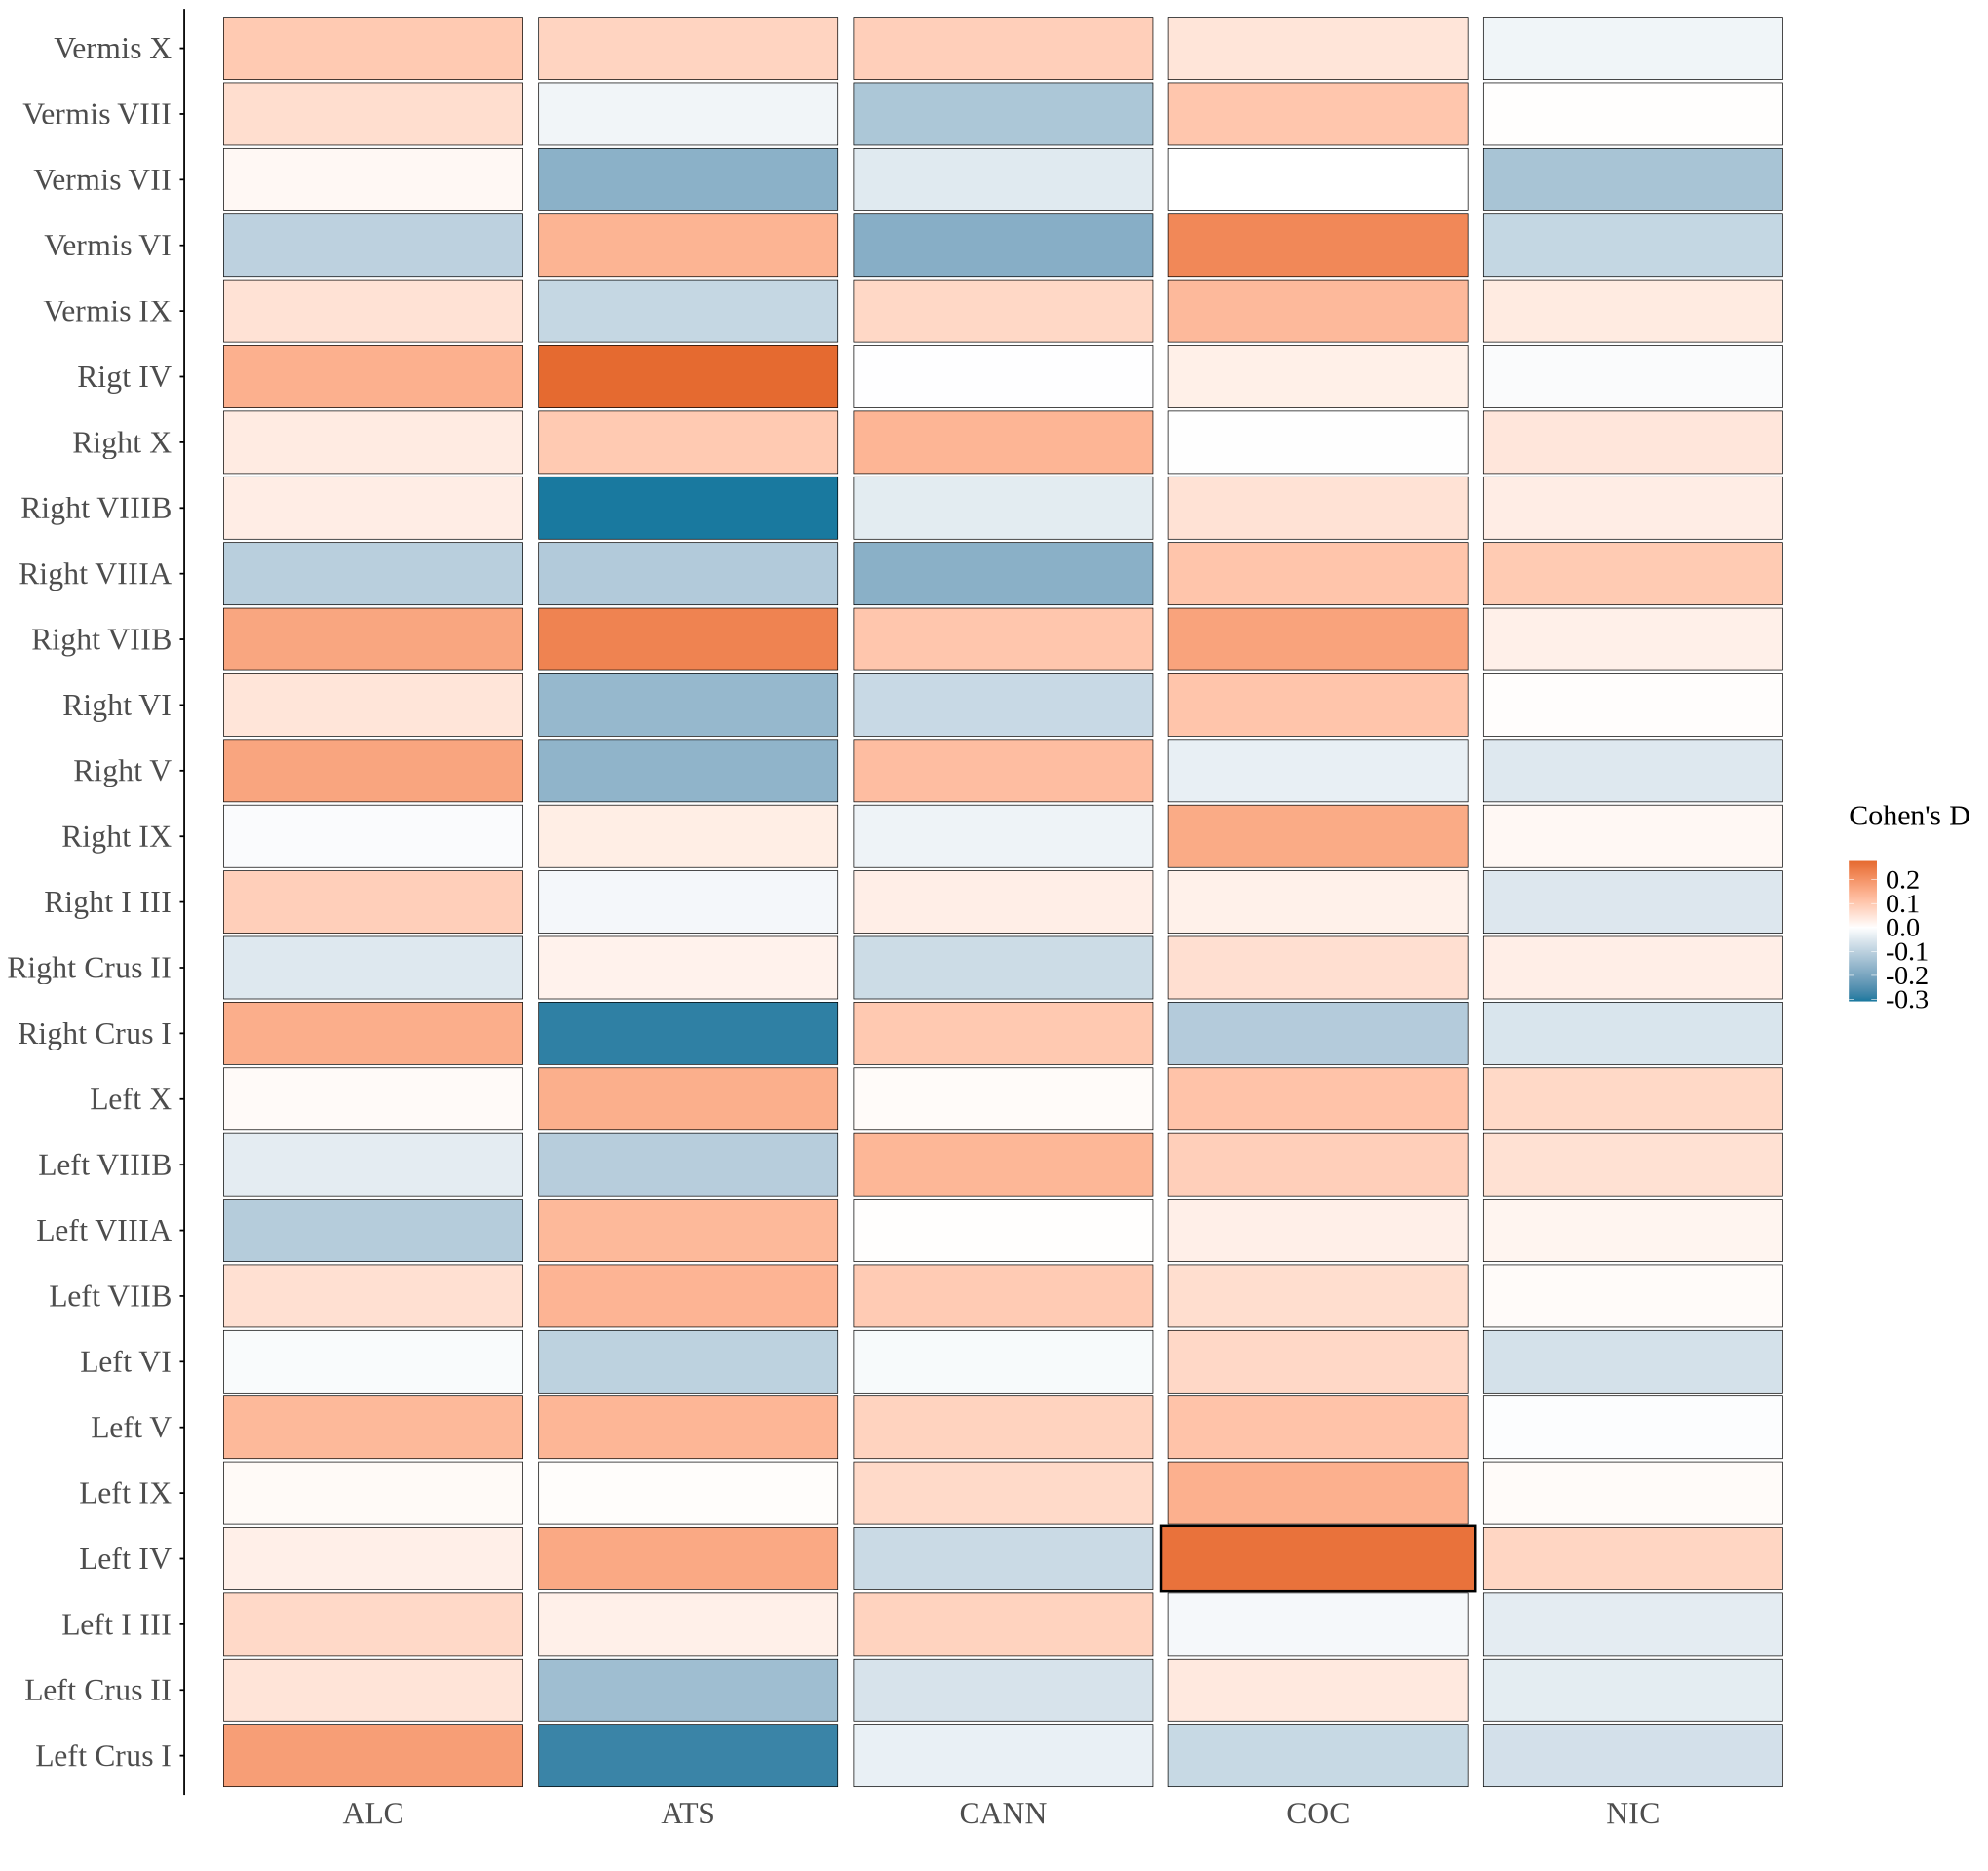

In [66]:
Acapulco_CA_cohend_plot

### **Figure S16** — Cov. Adjusted dataset: Cohen's D

In [65]:
# ── Cov. Adjusted (CA): Cohen's D heatmaps ─────────────────────────

# Acapulco — User vs HC
Acapulco_CA_user_d_2plot <- p_values_Acapulco_CA_user_vs_control %>%
    mutate(Group = "User",
           Cohens_d_AI = -effect.size) %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
           region = str_replace_all(region, "\\.", " "),
           region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
    left_join(
        Acapulco_user_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, significant_all),
        by = "region") 

plot_d_CA_Acapulco_user <- Acapulco_CA_user_d_2plot %>%
    ggplot(aes(x = Group, y = region, fill = Cohens_d_AI)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(Acapulco_CA_user_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale + theme_minimal() + theme_output +
    labs(title = "a) Volume differences (Alternative Imputation): Users vs Controls (Acapulco)",
         x = "", y = "", fill = "Cohen's D") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          axis.line.y = element_blank(),
          plot.title = element_text(size = 21, face = "bold", family = "Times New Roman"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# Acapulco — Substance vs HC
Acapulco_CA_substance_d_2plot <- p_values_Acapulco_CA_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "\\.", " "),
           Cohens_d_AI = -effect.size) %>%
    left_join(
        Acapulco_substance_merged_full_folds_matchit %>%
            mutate(region = case_when(region == "Rigt.IV" ~ "Right.IV", TRUE ~ region),
                   region = str_replace_all(region, "\\.", " "),
                   region = case_when(region == "Corpus Medullare" ~ "WM", TRUE ~ region)) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

Acapulco_CA_cohend_plot <- Acapulco_CA_substance_d_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_AI)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(Acapulco_CA_substance_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "Cohen's D", x = "", y = "Cerebellar region") +
    common_gradient_scale +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())

In [16]:
# MDTB — User vs HC
MDTB_CA_user_d_2plot <- p_values_MDTB_CA_user_vs_control %>%
    mutate(Group = "User",
           region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           Cohens_d_AI = -effect.size) %>%
    left_join(
        MDTB_user_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region ")) %>%
            select(region, significant_all),
        by = "region")

plot_d_CA_MDTB_user <- MDTB_CA_user_d_2plot %>%
    ggplot(aes(x = Group, y = region, fill = Cohens_d_AI)) +
    geom_tile(color = "black") +
    geom_tile(data = subset(MDTB_CA_user_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    common_gradient_scale + theme_minimal() + theme_output +
    labs(title = "b) Volume differences (Alternative Imputation): Users vs Controls (MDTB)",
         x = "", y = "", fill = "Cohen's D") +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
          axis.ticks.x = element_line(), axis.line.x = element_line(),
          plot.title = element_text(size = 21, face = "bold"),
          legend.position = "top",
          legend.title = element_text(size = 18, margin = margin(0,20,20,0)),
          legend.text = element_text(size = 17), legend.key.width = unit(1.5, "cm")) +
    coord_flip()

# MDTB — Substance vs HC
MDTB_CA_substance_d_2plot <- p_values_MDTB_CA_substance_vs_control %>%
    filter(!region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>%
    mutate(region = str_replace_all(region, "region_", "Region "),
           region = factor(region, levels = c("Region 1","Region 2","Region 3",
               "Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10")),
           Cohens_d_AI = -effect.size) %>%
    left_join(
        MDTB_substance_merged_full_folds_matchit %>%
            mutate(region = str_replace_all(region, "region_", "Region "),
                   region = factor(region, levels = c("Region 1","Region 2","Region 3","Region 4","Region 5","Region 6","Region 7","Region 8","Region 9","Region 10"))) %>%
            select(region, Substance, significant_all),
        by = c("region","Substance") )

MDTB_CA_cohend_plot <- MDTB_CA_substance_d_2plot %>%
    ggplot(aes(x = Substance, y = region, fill = Cohens_d_AI)) +
    geom_tile(color = "black", width = 0.95, height = 0.95) +
    geom_tile(data = subset(MDTB_CA_substance_d_2plot, significant_all == TRUE),
              color = "black", size = 0.7) +
    theme_minimal() + theme_output +
    labs(fill = "Cohen's D", x = "", y = "Cerebellar region") +
    common_gradient_scale +
    theme(axis.title.y = element_blank(), axis.title.x = element_text(size = 19),
          axis.text.x = element_text(size = 19), axis.text.y = element_text(size = 19),
          legend.position = "right",
          legend.title = element_text(size = 18, margin = margin(0,0,20,0)),
          legend.text = element_text(size = 17), legend.key.length = unit(1.5, "cm"),
          axis.ticks.y = element_line(), axis.line.y = element_line(),
          strip.text = element_text(size = 19),
          panel.grid.major = element_blank(), panel.grid.minor = element_blank())


In [17]:
# Compose Figure S16
Figure_S16_users <- wrap_plots(plot_d_CA_Acapulco_user) + wrap_plots(plot_d_CA_MDTB_user) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.5, 0.5)) +
    plot_annotation(title = "Complete cases: Users vs Controls (Cohen's D)") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
          plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

Figure_S16_first <- (Acapulco_CA_cohend_plot + 
    plot_pvalues_Acapulco_substance_vs_control_CA) +
    plot_layout(widths = c(0.4,0.6))

Figure_S16_second <- (MDTB_CA_cohend_plot +
    plot_pvalues_MDTB_substance_vs_control_CA) +
    plot_layout(widths = c(0.4,0.6))

Figure_S16 <- wrap_plots(Figure_S16_first) + wrap_plots(Figure_S16_second) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.7, 0.3)) +
    plot_annotation(tag_levels = "a", tag_suffix = ")",
        title = "Figure S16: Complete cases dataset — Cohen's D",
        theme = theme(plot.title = element_text(hjust = 0.5, size = 20)))

### **Figure S17**

In [18]:
Figure_S17 <- wrap_elements(plot_Acapulco_DK_trainTest + plot_Acapulco_DK_SplitHalf_U + plot_Acapulco_DK_SplitHalf_V + 
    plot_layout(ncol = 3)) +
    wrap_elements(plot_MDTB_DK_trainTest + plot_MDTB_DK_SplitHalf_U + plot_MDTB_DK_SplitHalf_V + 
    plot_layout(ncol = 3)) +
    plot_layout(nrow = 2, heights = c(0.6,0.4)) +
    plot_annotation(tag_levels = "a", tag_suffix = ")", 
        title = "PLS model performance",
        subtitle = "Training, Test, Split-half U and Split-half V") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 22))

### **Figure S18**

In [19]:
library(purrr)

plot_Acapulco_DK_LV_CI.u_dot_with_titles <- map2(plot_Acapulco_DK_LV_CI.u_dot, names(plot_Acapulco_DK_LV_CI.u_dot), ~ .x + ggtitle(.y))

Figure_S12_first <- wrap_plots(plot_Acapulco_DK_LV_CI.u_dot_with_titles[1:9]) +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S12_second <- wrap_plots(plot_Acapulco_DK_LV_CI.u_dot_with_titles[10:18]) +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S12_third <- wrap_plots(plot_Acapulco_DK_LV_CI.u_dot_with_titles[19:27]) +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S18 <- list(Figure_S12_first,Figure_S12_second,Figure_S12_third)

### **Figure S19**

In [20]:

plot_Acapulco_DK_LV_CI.v_dot_with_titles <- map2(plot_Acapulco_DK_LV_CI.v_dot, names(plot_Acapulco_DK_LV_CI.v_dot), ~ .x + ggtitle(.y))

Figure_S13_first <- wrap_plots(plot_Acapulco_DK_LV_CI.v_dot_with_titles[1:9]) +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S13_second <- wrap_plots(plot_Acapulco_DK_LV_CI.v_dot_with_titles[10:18]) +  
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S13_third <- wrap_plots(plot_Acapulco_DK_LV_CI.v_dot_with_titles[19:27]) +
    plot_layout(ncol = 3, nrow = 3,
    guides = "collect", axis_titles = "collect")

Figure_S19 <- list(Figure_S13_first,Figure_S13_second,Figure_S13_third)

### **Figure S20**

In [21]:
plot_MDTB_DK_LV_CI.u_dot_with_titles <- map2(plot_MDTB_DK_LV_CI.u_dot, names(plot_MDTB_DK_LV_CI.u_dot), ~ .x + ggtitle(.y))

Figure_S14_first <- wrap_plots(plot_MDTB_DK_LV_CI.u_dot_with_titles[1:6]) +
    plot_layout(ncol = 3, nrow = 2,
    guides = "collect", axis_titles = "collect")

Figure_S14_second <- wrap_plots(plot_MDTB_DK_LV_CI.u_dot_with_titles[7:10]) +
    plot_layout(ncol = 2, nrow = 2,
    guides = "collect", axis_titles = "collect")

Figure_S20 <- list(Figure_S14_first,Figure_S14_second)

### **Figure S21**

In [22]:
plot_MDTB_DK_LV_CI.v_dot_with_titles <- map2(plot_MDTB_DK_LV_CI.v_dot, names(plot_MDTB_DK_LV_CI.v_dot), ~ .x + ggtitle(.y))

Figure_S17_first <- wrap_plots(plot_MDTB_DK_LV_CI.v_dot_with_titles[1:6]) +
    plot_layout(ncol = 3, nrow = 2,
    guides = "collect", axis_titles = "collect")

Figure_S17_second <- wrap_plots(plot_MDTB_DK_LV_CI.v_dot_with_titles[7:10]) +
    plot_layout(ncol = 2, nrow = 2,
    guides = "collect", axis_titles = "collect")

Figure_S21 <- list(Figure_S17_first,Figure_S17_second)

## **Figures**

### **Figure 1**

#### Plot elements

In [9]:
Acapulco_cerebellar_tgwM_names <- Acapulco_volumes %>%
    select(Total_Cerebel_Vol,GM_Vol,Corpus.Medullare) %>% colnames()

    # boxplots 
    plots_Acapulco_user_tgwM <- map(Acapulco_cerebellar_tgwM_names, function(roi) {

        cuca = Acapulco_user_merged_full_folds_matchit %>% 
            filter(region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>% 
            filter(p_adj_median < 0.05,
                   !is.na(p.adj_matchit),
                   p.adj_matchit < 0.05,
                   !is.na(p.adj_CC), p.adj_CC < 0.05,
                   !is.na(p.adj_AI), p.adj_AI < 0.05) %>% 
            select(region, p.value_matchit, p.adj_matchit) %>%
            add_column(group = "User") %>%
            add_column(group1 = "HC") %>%
            mutate(group2 = "User",
                    .y. = roi) %>%
            add_significance("p.adj_matchit") %>% filter(region == roi)

        if (nrow(cuca) > 0) {
            Acapulco_volumes %>% 
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                group = factor(group, levels = c("HC","User"))) %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>%
            ggplot(aes(x = group, y = !!sym(roi), fill = group)) + 
            stat_halfeye(
                adjust = .8, width = .7, fill = "grey85",
                interval_colour = NA, 
                position = position_nudge(x = .01),
                aes(thickness = stat(f*n))) +
            geom_boxplot(outlier.colour = NA, 
                            notch = TRUE, 
                            alpha = 0.8, 
                            size = 1, 
                            width = 0.4, aes(fill = group)) +
            scale_fill_manual(values = pal_user) +
            scale_color_manual(values = pal_user) +
            xlab("") + ylab("Volume") +
            theme_ggdist() +
            theme_output +
            theme(strip.text = element_text(size = 16),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none") +
    stat_pvalue_manual(cuca, label = "p.adj_matchit.signif",
        y.position = Acapulco_volumes %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>% 
            select(roi) %>% 
            max() + 0.005, step.increase = 0.08,
        tip.length = 0.01, size = 8)

        } else {
            Acapulco_volumes %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>%
            mutate(group = factor(group, levels = c("HC","User"))) %>%
            ggplot(aes(x = group, y = !!sym(roi), fill = group)) + 
            stat_halfeye(
                adjust = .8, width = .7, fill = "grey85",
                interval_colour = NA, 
                position = position_nudge(x = .01),
                aes(thickness = stat(f*n))) +
            geom_boxplot(outlier.colour = NA, 
                            notch = TRUE, 
                            alpha = 0.8, 
                            size = 1, 
                            width = 0.4, aes(fill = group)) +
            scale_fill_manual(values = pal_user) +
            scale_color_manual(values = pal_user) +
            xlab("") + ylab("Volume") +
            theme_ggdist() +
            theme_output +
            theme(strip.text = element_text(size = 16),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none")
        } 
    }) %>% set_names(Acapulco_cerebellar_tgwM_names)

In [10]:
plot_Acapulco_user_controls_TGW <- ggarrange( 
        (plots_Acapulco_user_tgwM$GM_Vol + 
    labs(title = "Gray matter")) +
                theme(axis.text.x = element_text(size = 20),
                plot.title = element_text(size = 20, hjust = 0.5, face = "bold", margin=margin(0,0,30,0))), 
        (plots_Acapulco_user_tgwM$Corpus.Medullare + 
    labs(title = "White matter")) +
                theme(axis.text.x = element_text(size = 20),
                axis.title.y = element_blank(),
                plot.title = element_text(size = 20, hjust = 0.5, face = "bold", margin=margin(0,0,30,0))),
        (plots_Acapulco_user_tgwM$Total_Cerebel_Vol + 
    labs(title = "Total") +
                theme(axis.text.x = element_text(size = 20),
                axis.title.y = element_blank(),
                plot.title = element_text(size = 20, hjust = 0.5, face = "bold", margin=margin(0,0,30,0)))), 
                labels = c("A", "B", "C"), font.label = list(size = 25, family = "Times New Roman"),
                ncol = 3)

In [11]:
Acapulco_cerebellar_tgwM_names <- Acapulco_volumes %>%
    select(Total_Cerebel_Vol,GM_Vol,Corpus.Medullare) %>% colnames()

p_values_Acapulco_substance_vs_control_filtered <- Acapulco_substance_merged_full_folds_matchit %>%
    filter(region %in% c("Total_Cerebel_Vol", "GM_Vol", "Corpus.Medullare")) %>% 
    filter(p_adj_median < 0.05,
           !is.na(p_adj_matchit),
           p_adj_matchit < 0.05,
           !is.na(p.adj_CC), p.adj_CC < 0.05,
           !is.na(p.adj_AI), p.adj_AI < 0.05)

    # boxplots 
    plots_Acapulco_substances_tgwM <- map(Acapulco_cerebellar_tgwM_names, function(roi) {

        cuca = p_values_Acapulco_substance_vs_control_filtered %>% 
            select(Substance, region, p_value_matchit, p_adj_matchit) %>%
            add_column(group1 = "HC") %>%
            mutate(group2 = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                    .y. = roi) %>%
            add_significance("p_adj_matchit") %>% filter(region == roi)

        Acapulco_volumes %>% 
            mutate(Substance = factor(Substance, levels = c("HC","ALC","ATS","CANN","COC","NIC","OPI")),
                group = factor(group, levels = c("HC","User"))) %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>%
            ggplot(aes(x = Substance, y = !!sym(roi), fill = Substance)) + 
            stat_halfeye(
                adjust = .8, width = .7, fill = "grey85",
                interval_colour = NA, 
                position = position_nudge(x = .01),
                aes(thickness = stat(f*n))) +
            geom_boxplot(outlier.colour = NA, 
                            notch = TRUE, 
                            alpha = 0.8, 
                            size = 1, 
                            width = 0.4, aes(fill = Substance)) +
            scale_fill_manual(values = pal_substances) +
            scale_color_manual(values = pal_substances) +
            xlab("") + ylab("Volume") +
            theme_ggdist() +
            theme_output +
            theme(strip.text = element_text(size = 16),
                    strip.background = element_rect(fill = "white"),
                    legend.position = "none") + 
    stat_pvalue_manual(cuca, label = "p_adj_matchit.signif",
        y.position = Acapulco_volumes %>%
            filter(!is_outlier(!!sym(roi), 2.5)) %>% 
            select(roi) %>% 
            max() + 0.005, step.increase = 0.08,
        tip.length = 0.01, size = 8) 
    }) %>% set_names(Acapulco_cerebellar_tgwM_names)

In [12]:
plot_Acapulco_substance_controls_TGW <- ggarrange( 
        (plots_Acapulco_substances_tgwM$GM_Vol + 
    labs(title = "Gray matter")) +
                theme(axis.text.x = element_text(size = 20),
                plot.title = element_text(size = 20, hjust = 0.5, face = "bold", margin=margin(0,0,30,0))), 
        (plots_Acapulco_substances_tgwM$Corpus.Medullare + 
    labs(title = "White matter")) +
                theme(axis.text.x = element_text(size = 20),
                axis.title.y = element_blank(),
                plot.title = element_text(size = 20, hjust = 0.5, face = "bold", margin=margin(0,0,30,0))),
        (plots_Acapulco_substances_tgwM$Total_Cerebel_Vol + 
    labs(title = "Total") +
                theme(axis.text.x = element_text(size = 20),
                axis.title.y = element_blank(),
                plot.title = element_text(size = 20, hjust = 0.5, face = "bold", margin=margin(0,0,30,0)))), 
                labels = c("D", "E", "F"), font.label = list(size = 25, family = "Times New Roman"),
                ncol = 3)

#### Plot

In [13]:
Figure_1 <- (plot_Acapulco_user_controls_TGW) / 
    (plot_Acapulco_substance_controls_TGW) + 
    plot_layout(heights = c(1,1)) &
    theme(plot.title = element_text(size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 25))

### **Figure 2**

#### T-values

In [16]:
Acapulco_tval_users <- Acapulco_user_merged_full_folds_matchit %>%
    group_by(region) %>%
    mutate(statistic_matchit = case_when(significant_all == TRUE ~ statistic_matchit)) %>% 
    select(statistic_matchit)

MDTB_tval_users <- MDTB_user_merged_full_folds_matchit %>%
    group_by(region) %>%
    mutate(statistic_matchit = case_when(significant_all == TRUE ~ statistic_matchit)) %>% 
    select(statistic_matchit)

Acapulco_tval_substances <- substances_names %>% 
        map(~ Acapulco_substance_merged_full_folds_matchit %>% 
        group_by(region,Substance) %>%
    mutate(statistic_matchit = case_when(significant_all == TRUE ~ statistic_matchit)) %>% 
    select(statistic_matchit) %>% filter(Substance == .x)) %>% set_names(substances_names)

MDTB_tval_substances <- substances_names %>% 
        map(~ MDTB_substance_merged_full_folds_matchit %>% 
        group_by(region,Substance) %>%
    mutate(statistic_matchit = case_when(significant_all == TRUE ~ statistic_matchit)) %>% 
    select(statistic_matchit) %>% filter(Substance == .x)) %>% set_names(substances_names)

Adding missing grouping variables: `region`
Adding missing grouping variables: `region`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`


In [17]:
users_min_max_bases_acapulco <- bind_rows(Acapulco_tval_users, .id = "Substance") %>%
    filter(!region %in% c("Corpus.Medullare", "Total_Cerebel_Vol", "GM_Vol"))
users_min_max_bases_mdtb <- bind_rows(MDTB_tval_users, .id = "Substance")

substance_min_max_bases_acapulco <- bind_rows(Acapulco_tval_substances, .id = "Substance") %>%
    filter(!region %in% c("Corpus.Medullare", "Total_Cerebel_Vol", "GM_Vol"))
substance_min_max_bases_mdtb <- bind_rows(MDTB_tval_substances, .id = "Substance") %>%
    filter(!region %in% c("Corpus.Medullare", "Total_Cerebel_Vol", "GM_Vol"))
min_max_bases_acapulco <- bind_rows(users_min_max_bases_acapulco, substance_min_max_bases_acapulco)
min_max_bases_mdtb <- bind_rows(users_min_max_bases_mdtb, substance_min_max_bases_mdtb)

In [18]:
color_gradient2_acapulco <- create_color_gradient2(min_max_bases_acapulco$statistic_matchit %>% min(na.rm = TRUE), 
    min_max_bases_acapulco$statistic_matchit %>% max(na.rm = TRUE))
color_gradient2_mdtb <- create_color_gradient2(min_max_bases_mdtb$statistic_matchit %>% min(na.rm = TRUE),
    min_max_bases_mdtb$statistic_matchit %>% max(na.rm = TRUE))

In [19]:
Acapulco_tval_flatmap_users <- read.table("Figures/Flatmap/Acapulco/atl-Anatom.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "\\_", " ")) %>% rename("Region" = "V5") %>%
        left_join(Acapulco_tval_users %>% rename("Region" = "region") %>% ungroup() %>%
                add_row(Region = "dummy", 
                        statistic_matchit = round(min_max_bases_acapulco$statistic_matchit %>% min(na.rm = TRUE))) %>% 
                add_row(Region = "dummy2", 
                        statistic_matchit = round(min_max_bases_acapulco$statistic_matchit %>% max(na.rm = TRUE))) %>%
                mutate(hex_rgb = color_gradient2_acapulco(statistic_matchit)) %>%
        # filter(Region != c("Corpus.Medullare","dummy","dummy2")) %>%
        mutate(Region = str_replace_all(Region, "\\.", " "))) %>%
        mutate(hex_rgb = case_when(is.na(statistic_matchit) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb) %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame()

MDTB_tval_flatmap_users <- read.table("Figures/Flatmap/MDTB/atl-MDTB10.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "Region", "region ")) %>% rename("Region" = "V5") %>%
        left_join(MDTB_tval_users %>% rename("Region" = "region") %>% ungroup() %>%
                add_row(Region = "dummy", 
                        statistic_matchit = round(min_max_bases_mdtb$statistic_matchit %>% min(na.rm = TRUE))) %>% 
                add_row(Region = "dummy2", 
                        statistic_matchit = round(min_max_bases_mdtb$statistic_matchit %>% max(na.rm = TRUE))) %>%
                mutate(hex_rgb = color_gradient2_mdtb(statistic_matchit)) %>%
        # filter(Region != c("Corpus.Medullare","dummy","dummy2")) %>%
        mutate(Region = str_replace_all(Region, "\\_", " "))) %>%
        mutate(hex_rgb = case_when(is.na(statistic_matchit) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb) %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame()

Acapulco_tval_flatmap_substances <- substances_names %>% 
        map(~ read.table("Figures/Flatmap/Acapulco/atl-Anatom.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "\\_", " ")) %>% rename("Region" = "V5") %>%
        left_join(Acapulco_tval_substances[[.x]] %>% rename("Region" = "region") %>% ungroup() %>%
                add_row(Region = "dummy", 
                        statistic_matchit = round(min_max_bases_acapulco$statistic_matchit %>% min(na.rm = TRUE))) %>% 
                add_row(Region = "dummy2", 
                        statistic_matchit = round(min_max_bases_acapulco$statistic_matchit %>% max(na.rm = TRUE))) %>%
                mutate(hex_rgb = color_gradient2_acapulco(statistic_matchit)) %>%
        # filter(Region != c("Corpus.Medullare","dummy","dummy2")) %>%
        mutate(Region = str_replace_all(Region, "\\.", " "))) %>%
        mutate(hex_rgb = case_when(is.na(statistic_matchit) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb) %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame()) %>% 
            set_names(substances_names)

MDTB_tval_flatmap_substances <- substances_names %>%
        map(~ read.table("Figures/Flatmap/MDTB/atl-MDTB10.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "Region", "region ")) %>% rename("Region" = "V5") %>%
        left_join(MDTB_tval_substances[[.x]] %>% rename("Region" = "region") %>% ungroup() %>%
                add_row(Region = "dummy", 
                        statistic_matchit = round(min_max_bases_mdtb$statistic_matchit %>% min(na.rm = TRUE))) %>% 
                add_row(Region = "dummy2", 
                        statistic_matchit = round(min_max_bases_mdtb$statistic_matchit %>% max(na.rm = TRUE))) %>%
                mutate(hex_rgb = color_gradient2_mdtb(statistic_matchit)) %>%
        # filter(Region != c("Corpus.Medullare","dummy","dummy2")) %>%
        mutate(Region = str_replace_all(Region, "\\_", " "))) %>%
        mutate(hex_rgb = case_when(is.na(statistic_matchit) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb) %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame()) %>% 
            set_names(substances_names)

Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`


In [20]:
dir.create("Figures/Flatmap/Acapulco/permutation_flatmap/",showWarnings = FALSE, recursive = TRUE)
iwalk(Acapulco_tval_flatmap_substances, ~ write.table(.x, 
    file = paste0("Figures/Flatmap/Acapulco/permutation_flatmap/", .y, "_perm_acapulco_rgb4Flatmap_tval.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE))

dir.create("Figures/Flatmap/MDTB/permutation_flatmap/",showWarnings = FALSE, recursive = TRUE)
iwalk(MDTB_tval_flatmap_substances, ~ write.table(.x, 
    file = paste0("Figures/Flatmap/MDTB/permutation_flatmap/", .y, "_perm_MDTB_rgb4Flatmap_tval.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE))

write.table(Acapulco_tval_flatmap_users,
    file = paste0("Figures/Flatmap/Acapulco/permutation_flatmap/users_perm_acapulco_rgb4Flatmap_tval.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE)

write.table(MDTB_tval_flatmap_users,
    file = paste0("Figures/Flatmap/MDTB/permutation_flatmap/users_perm_MDTB_rgb4Flatmap_tval.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE)

#### Cohen's D

In [21]:
Acapulco_Cohens_users <- Acapulco_user_merged_full_folds_matchit %>%
    group_by(region) %>%
    mutate(Cohens_d_matchit = -effect.size_matchit) %>%
    select(Cohens_d_matchit)

MDTB_Cohens_users <- MDTB_user_merged_full_folds_matchit %>%
    group_by(region) %>%
    mutate(Cohens_d_matchit = -effect.size_matchit) %>%
    select(Cohens_d_matchit)

Acapulco_Cohens_substances <- substances_names %>% 
        map(~ Acapulco_substance_merged_full_folds_matchit %>% 
        group_by(region,Substance) %>%
    mutate(Cohens_d_matchit = -effect.size_matchit) %>%
    select(Cohens_d_matchit) %>% filter(Substance == .x)) %>% set_names(substances_names)

MDTB_Cohens_substances <- substances_names %>% 
        map(~ MDTB_substance_merged_full_folds_matchit %>% 
        group_by(region,Substance) %>%
    mutate(Cohens_d_matchit = -effect.size_matchit) %>%
    select(Cohens_d_matchit) %>% filter(Substance == .x)) %>% set_names(substances_names)


Adding missing grouping variables: `region`
Adding missing grouping variables: `region`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`
Adding missing grouping variables: `region`, `Substance`


In [22]:
users_min_max_bases_acapulco_cohensd <- bind_rows(Acapulco_Cohens_users, .id = "Substance") %>%
    filter(!region %in% c("Corpus.Medullare", "Total_Cerebel_Vol", "GM_Vol"))
users_min_max_bases_mdtb_cohensd <- bind_rows(MDTB_Cohens_users, .id = "Substance")

substance_min_max_bases_acapulco_cohends <- bind_rows(Acapulco_Cohens_substances, .id = "Substance") %>%
    filter(!region %in% c("Corpus.Medullare", "Total_Cerebel_Vol", "GM_Vol"))
substance_min_max_bases_mdtb_cohends <- bind_rows(MDTB_Cohens_substances, .id = "Substance") %>%
    filter(!region %in% c("Corpus.Medullare", "Total_Cerebel_Vol", "GM_Vol"))
min_max_bases_acapulco <- bind_rows(users_min_max_bases_acapulco_cohensd, substance_min_max_bases_acapulco_cohends)
min_max_bases_mdtb <- bind_rows(users_min_max_bases_mdtb_cohensd, substance_min_max_bases_mdtb_cohends)

In [23]:
min_max_bases_acapulco$Cohens_d_matchit %>% min(na.rm = TRUE)
min_max_bases_acapulco$Cohens_d_matchit %>% max(na.rm = TRUE)

[1] -0.3679111

[1] 0.3357783

In [24]:
color_gradient_acapulco <- create_color_gradient(min_max_bases_acapulco$Cohens_d_matchit %>% min(na.rm = TRUE), 
    min_max_bases_acapulco$Cohens_d_matchit %>% max(na.rm = TRUE))
color_gradient_mdtb <- create_color_gradient(min_max_bases_mdtb$Cohens_d_matchit %>% min(na.rm = TRUE),
    min_max_bases_mdtb$Cohens_d_matchit %>% max(na.rm = TRUE))

In [25]:
Acapulco_Cohens_flatmap_users <- read.table("Figures/Flatmap/Acapulco/atl-Anatom.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "\\_", " ")) %>% rename("Region" = "V5") %>%
        left_join(Acapulco_Cohens_users %>% rename("Region" = "region") %>% ungroup() %>%
                add_row(Region = "dummy", 
                    Cohens_d_matchit = round(min_max_bases_acapulco$Cohens_d_matchit %>% min(na.rm = TRUE),2)) %>% 
                add_row(Region = "dummy2", 
                    Cohens_d_matchit = round(min_max_bases_acapulco$Cohens_d_matchit %>% max(na.rm = TRUE),2)) %>%
                mutate(hex_rgb = color_gradient_acapulco(Cohens_d_matchit)) %>%
        # filter(Region != c("Corpus.Medullare","dummy","dummy2")) %>%
        mutate(Region = str_replace_all(Region, "\\.", " "))) %>%
        mutate(hex_rgb = case_when(is.na(Cohens_d_matchit) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb) %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame()

MDTB_Cohens_flatmap_users <- read.table("Figures/Flatmap/MDTB/atl-MDTB10.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "Region", "region ")) %>% rename("Region" = "V5") %>%
        left_join(MDTB_Cohens_users %>% rename("Region" = "region") %>% ungroup() %>%
                add_row(Region = "dummy", 
                        Cohens_d_matchit = round(min_max_bases_mdtb$Cohens_d_matchit %>% min(na.rm = TRUE),2)) %>% 
                add_row(Region = "dummy2", 
                        Cohens_d_matchit = round(min_max_bases_mdtb$Cohens_d_matchit %>% max(na.rm = TRUE),2)) %>%
                mutate(hex_rgb = color_gradient_mdtb(Cohens_d_matchit)) %>%
        # filter(Region != c("Corpus.Medullare","dummy","dummy2")) %>%
        mutate(Region = str_replace_all(Region, "\\_", " "))) %>%
        mutate(hex_rgb = case_when(is.na(Cohens_d_matchit) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb) %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame()

Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`


In [26]:
Acapulco_Cohens_flatmap_substances <- substances_names %>% 
        map(~ read.table("Figures/Flatmap/Acapulco/atl-Anatom.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "\\_", " ")) %>% rename("Region" = "V5") %>%
        left_join(Acapulco_Cohens_substances[[.x]] %>% rename("Region" = "region") %>% ungroup() %>%
                add_row(Region = "dummy", 
                        Cohens_d_matchit = round(min_max_bases_acapulco$Cohens_d_matchit %>% min(na.rm = TRUE),2)) %>% 
                add_row(Region = "dummy2", 
                        Cohens_d_matchit = round(min_max_bases_acapulco$Cohens_d_matchit %>% max(na.rm = TRUE),2)) %>%
                mutate(hex_rgb = color_gradient_acapulco(Cohens_d_matchit)) %>%
        # filter(Region != c("Corpus.Medullare","dummy","dummy2")) %>%
        mutate(Region = str_replace_all(Region, "\\.", " "))) %>%
        mutate(hex_rgb = case_when(is.na(Cohens_d_matchit) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb) %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame()) %>% 
            set_names(substances_names)

MDTB_Cohens_flatmap_substances <- substances_names[-3] %>% 
        map(~ read.table("Figures/Flatmap/MDTB/atl-MDTB10.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "Region", "region ")) %>% rename("Region" = "V5") %>%
        left_join(MDTB_Cohens_substances[[.x]] %>% rename("Region" = "region") %>% ungroup() %>%
                add_row(Region = "dummy", 
                        Cohens_d_matchit = round(min_max_bases_mdtb$Cohens_d_matchit %>% min(na.rm = TRUE),2)) %>% 
                add_row(Region = "dummy2", 
                        Cohens_d_matchit = round(min_max_bases_mdtb$Cohens_d_matchit %>% max(na.rm = TRUE),2)) %>%
                mutate(hex_rgb = color_gradient_mdtb(Cohens_d_matchit)) %>%
        # filter(Region != c("Corpus.Medullare","dummy","dummy2")) %>%
        mutate(Region = str_replace_all(Region, "\\_", " "))) %>%
        mutate(hex_rgb = case_when(is.na(Cohens_d_matchit) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb)  %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame()) %>%
            set_names(substances_names[-3])

Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`


In [27]:
dir.create("Figures/Flatmap/Acapulco/permutation_flatmap/",showWarnings = FALSE, recursive = TRUE)
iwalk(Acapulco_Cohens_flatmap_substances, ~ write.table(.x, 
    file = paste0("Figures/Flatmap/Acapulco/permutation_flatmap/", .y, "_perm_acapulco_rgb4Flatmap.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE))

dir.create("Figures/Flatmap/MDTB/permutation_flatmap/",showWarnings = FALSE, recursive = TRUE)
iwalk(MDTB_Cohens_flatmap_substances, ~ write.table(.x, 
    file = paste0("Figures/Flatmap/MDTB/permutation_flatmap/", .y, "_perm_MDTB_rgb4Flatmap.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE))

write.table(Acapulco_Cohens_flatmap_users,
    file = paste0("Figures/Flatmap/Acapulco/permutation_flatmap/users_perm_acapulco_rgb4Flatmap.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE)

write.table(MDTB_Cohens_flatmap_users,
    file = paste0("Figures/Flatmap/MDTB/permutation_flatmap/users_perm_MDTB_rgb4Flatmap.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE)

### **Figure 3** — Acapulco: User vs HC across all 4 analysis strategies

#### Settings

In [10]:

# ── Shared palette / shapes for the 4 analysis strategies ─────────────────────
pal_strategy <- c(
    "Full sample"     = "#3A5589",
    "Matched sample"  = "#EB8F33",
    "Folds sample (Median)"="#eb3333",
    "Complete cases"  = "#0B8755",
    "Alt. imputation" = "#764EA1"
)
shape_strategy <- c(
    "Full sample"     = 19,   # filled circle
    "Matched sample"  = 17,   # filled triangle up
    "Folds sample (Median)"    = 20,   
    "Complete cases"  = 15,   # filled square
    "Alt. imputation" = 18,   # filled diamond
    "Cov. Adjusted" = 24    # filled triangle down
)
strategy_levels <- names(pal_strategy)

# ── Helper: normalise p-value column name and select key columns ───────────────
# Primary/matchit User-vs-HC use p.adj (dot); substances + CC/AI use p_adj (underscore).
std_pvals <- function(df, strategy_label, extra_cols = character(0)) {
    if ("p.adj" %in% names(df)) df <- df %>% dplyr::rename(p_adj = p.adj)
    df %>%
        select(all_of(c(extra_cols, "region", "effect.size", "p_adj"))) %>%
        mutate(strategy = strategy_label)
}

# ── Load MDTB sanity-check results if not already in session ───────────────────
if (!exists("p_values_MDTB_CC_user_vs_control")) {
    load("Statistics/Sanity_check/MDTB/MDTB_sanity_check_statistics.RData")
}




In [11]:
median_p_values_Acapulco_folds_users_vs_control <- p_values_Acapulco_folds_users_vs_control %>% 
    group_by(region, term) %>%
    summarise(
        across(where(is.numeric), ~ median(.x, na.rm = TRUE)),
        .groups = "drop"
    ) 
median_p_values_Acapulco_folds_substance_vs_control <- p_values_Acapulco_folds_substance_vs_control %>% 
    group_by(region, term, Substance) %>%
    summarise(
        across(where(is.numeric), ~ median(.x, na.rm = TRUE)),
        .groups = "drop"
    ) 

In [12]:
p_values_Acapulco_samples_user_vs_control <- p_values_Acapulco_user_vs_control %>%
    rename_with(~ paste0(.x, "_full"), -any_of(c("region", "term"))) %>%
    left_join(p_values_Acapulco_matchit_users_vs_control %>%
        rename_with(~ paste0(.x, "_matched"), -any_of(c("region", "term"))), 
        by = c("region", "term")) %>%
    left_join(median_p_values_Acapulco_folds_users_vs_control %>%
        rename_with(~ paste0(.x, "_folds"), -any_of(c("region", "term"))), 
        by = "region") %>%
    left_join(p_values_Acapulco_CC_user_vs_control %>%
        rename_with(~ paste0(.x, "_CC"), -any_of(c("region", "term"))), 
        by = "region") %>%
    left_join(p_values_Acapulco_AI_user_vs_control %>%
        rename_with(~ paste0(.x, "_AI"), -any_of(c("region", "term"))), 
        by = "region") %>%
    mutate(p.adj_significant = ifelse(p.adj_full < 0.05 & p.adj_matched < 0.05 & p_adj_folds < 0.05 & p.adj_CC < 0.05 & p.adj_AI < 0.05, p.adj_matched, NA))

p_values_Acapulco_samples_substance_vs_control <- p_values_Acapulco_substance_vs_control %>%
    rename_with(~ paste0(.x, "_full"), -any_of(c("region", "term", "Substance"))) %>%
    left_join(p_values_Acapulco_matchit_substance_vs_control %>%
        rename_with(~ paste0(.x, "_matched"), -any_of(c("region", "term", "Substance"))), 
        by = c("region", "term", "Substance")) %>%
    left_join(median_p_values_Acapulco_folds_substance_vs_control %>%
        rename_with(~ paste0(.x, "_folds"), -any_of(c("region", "term", "Substance"))), 
        by = c("region", "term", "Substance")) %>%
    left_join(p_values_Acapulco_CC_substance_vs_control %>%
        rename_with(~ paste0(.x, "_CC"), -any_of(c("region", "term", "Substance"))), 
        by = c("region", "term", "Substance")) %>%
    left_join(p_values_Acapulco_AI_substance_vs_control %>%
        rename_with(~ paste0(.x, "_AI"), -any_of(c("region", "term", "Substance"))), 
        by = c("region", "term", "Substance")) %>%
    mutate(p.adj_significant = ifelse(p_adj_full < 0.05 & p_adj_matched < 0.05 & p_adj_folds < 0.05 & p.adj_CC < 0.05 & p.adj_AI < 0.05, p_adj_matched, NA))

#### Figure 3a

In [13]:

# ── Combine all 4 strategies: Acapulco User vs HC ─────────────────────────────
strat_acap_user <- bind_rows(
    std_pvals(p_values_Acapulco_user_vs_control,          "Full sample"),
    std_pvals(p_values_Acapulco_matchit_users_vs_control,  "Matched sample"),
    std_pvals(median_p_values_Acapulco_folds_users_vs_control, "Folds sample (Median)"),
    std_pvals(p_values_Acapulco_CC_user_vs_control,        "Complete cases"),
    std_pvals(p_values_Acapulco_AI_user_vs_control,        "Alt. imputation"),
    std_pvals(p_values_Acapulco_CA_user_vs_control,           "Cov. Adjusted")
) %>%
    mutate(strategy = factor(strategy, levels = strategy_levels),
        effect.size = -effect.size)  # flip sign so that positive = user > HC

# Regions significant in primary analysis → drawn at full opacity
sig_primary_acap <- p_values_Acapulco_samples_user_vs_control %>%
    { if ("p.adj_significant" %in% names(.)) rename(., p.adj_significant = p.adj_significant) else . } %>%
    filter(!is.na(p.adj_significant), p.adj_significant < 0.05) %>%
    pull(region) %>% unique()

# Sort regions by matched-sample effect size (ascending = top = most positive)
region_order_acap <- strat_acap_user %>%
    filter(strategy == "Matched sample") %>%
    arrange(effect.size) %>%
    pull(region)

strat_acap_user <- strat_acap_user %>%
    mutate(
        region      = factor(region, levels = region_order_acap),
        sig_primary = region %in% sig_primary_acap
    )

region_order_acap <- region_order_acap %>%
    gsub("\\.", " ", .) %>%
    gsub("Total_Cerebel_Vol", "Total Cerebellum", .) %>%
    gsub("GM_Vol", "GM Volume", .) %>%
    gsub("Corpus Medullare", "WM Volume", .) %>%
    gsub("Rigt", "Right ", .)

sig_primary_acap <- sig_primary_acap %>%
    gsub("\\.", " ", .) %>%
    gsub("Total_Cerebel_Vol", "Total Cerebellum", .) %>%
    gsub("GM_Vol", "GM Volume", .) %>%
    gsub("Corpus Medullare", "WM Volume", .) %>%
    gsub("Rigt", "Right ", .)

strat_acap_user <- strat_acap_user %>%
    mutate(
        region = factor(
            gsub("\\.", " ", as.character(region)) %>%
                gsub("Total_Cerebel_Vol", "Total Cerebellum", .) %>%
                gsub("GM_Vol", "GM Volume", .) %>%
                gsub("Corpus Medullare", "WM Volume", .) %>%
                gsub("Rigt", "Right ", .),
            levels = region_order_acap
        )
    )

Figure_3a <- strat_acap_user %>%
    ggplot(aes(
        x     = region,
        y     = effect.size,
        color = strategy,
        shape = strategy,
        alpha = sig_primary
    )) +
    geom_hline(yintercept = 0, color = "grey70", linewidth = 0.5) +
    geom_point(
        size     = 3.5,
        position = position_dodge(width = 0.75),
        stroke   = 0
    ) +
    scale_color_manual(values = pal_strategy,   name = "Analysis strategy") +
    scale_shape_manual(values = shape_strategy, name = "Analysis strategy") +
    scale_alpha_manual(
        values = c("TRUE" = 1.0, "FALSE" = 0.35),
        name   = "FDR < 0.05",
        labels = c("No", "Yes"),
        guide  = guide_legend(override.aes = list(size = 4, color = "grey40"))
    ) +
    labs(x = "", y = "Cohen's d") +
    theme_bw(base_size = 13) +
    theme_output +
    theme(
        axis.text.x      = element_text(size = 16, angle = 45, hjust = 1),
        axis.text.y      = element_text(size = 13),
        axis.title.y     = element_text(size = 18, margin = margin(l = 55, r = -55)),
        panel.grid.minor = element_blank(),
        legend.text      = element_text(size = 18),
        legend.title     = element_text(size = 20),
        legend.position  = "none"
    )




#### Figure 3b

In [14]:

# ── Combine all 4 strategies: Acapulco Substance vs HC ────────────────────────
strat_acap_sub <- bind_rows(
    std_pvals(p_values_Acapulco_substance_vs_control,          "Full sample",
              extra_cols = "Substance"),
    std_pvals(p_values_Acapulco_matchit_substance_vs_control,  "Matched sample",
              extra_cols = "Substance"),
    std_pvals(median_p_values_Acapulco_folds_substance_vs_control, "Folds sample (Median)",
              extra_cols = "Substance"),
    std_pvals(p_values_Acapulco_CC_substance_vs_control,       "Complete cases",
              extra_cols = "Substance"),
    std_pvals(p_values_Acapulco_AI_substance_vs_control,       "Alt. imputation",
              extra_cols = "Substance"),
    std_pvals(p_values_Acapulco_CA_substance_vs_control,       "Cov. Adjusted",
              extra_cols = "Substance")
) %>%
    mutate(
        strategy  = factor(strategy, levels = strategy_levels),
        Substance = factor(Substance, levels = c("ALC","ATS","CANN","COC","NIC")),
        effect.size = -effect.size)  # flip sign so that positive = user > HC

sig_primary_sub <- p_values_Acapulco_samples_substance_vs_control %>%
    filter(!is.na(p.adj_significant), p.adj_significant < 0.05) %>%
    mutate(key = paste(Substance, region, sep = "_")) %>%
    pull(key)

strat_acap_sub <- strat_acap_sub %>%
    mutate(sig_primary = paste(Substance, region, sep = "_") %in% sig_primary_sub)

# ── Panel a: Total Cerebellar Volume summary ───────────────────────────────────
Figure_3_summary <- strat_acap_sub %>%
    filter(region == "Total_Cerebel_Vol") %>%
    ggplot(aes(
        x     = Substance,
        y     = effect.size,
        color = strategy,
        shape = strategy,
        alpha = sig_primary
    )) +
    geom_hline(yintercept = 0, color = "grey70", linewidth = 0.5) +
    geom_point(
        size     = 5,
        position = position_dodge(width = 0.6),
        stroke   = 0
    ) +
    scale_color_manual(values = pal_strategy,   name = "Analysis strategy") +
    scale_shape_manual(values = shape_strategy, name = "Analysis strategy") +
    scale_alpha_manual(
        values = c("TRUE" = 1.0, "FALSE" = 0.35),
        name   = "FDR < 0.05",
        labels = c("No", "Yes")
    ) +
    labs(
        x     = "Substance group",
        y     = "Cohen's d",
        title = "Total Cerebellar Volume"
    ) +
    theme_bw(base_size = 13) +
    theme_output +
    theme(
        plot.title   = element_text(hjust = 0.5, size = 22),
        axis.text    = element_text(size = 20),
        legend.text  = element_text(size = 18),
        legend.title = element_text(size = 20)
    )

# ── Panel b: All Acapulco regions — faceted by substance ──────────────────────
region_order_sub <- strat_acap_sub %>%
    filter(strategy == "Matched sample", Substance == "ALC") %>%
    arrange(effect.size) %>%
    pull(region)

region_order_sub <- region_order_sub %>%
    gsub("\\.", " ", .) %>%
    gsub("Total_Cerebel_Vol", "Total Cerebellum", .) %>%
    gsub("GM_Vol", "GM Volume", .) %>% 
    gsub("Corpus Medullare", "WM Volume", .) %>%
    gsub("Rigt", "Right ", .)

strat_acap_sub <- strat_acap_sub %>%
    mutate(
        region = gsub("\\.", " ", region) %>%
            gsub("Total_Cerebel_Vol", "Total Cerebellum", .) %>%
            gsub("GM_Vol", "GM Volume", .) %>%
            gsub("Corpus Medullare", "WM Volume", .) %>%
            gsub("Rigt", "Right ", .)
    )

Figure_3b <- strat_acap_sub %>%
    mutate(region = factor(region, levels = region_order_sub)) %>%
    ggplot(aes(
        x     = effect.size,
        y     = region,
        color = strategy,
        shape = strategy,
        alpha = sig_primary
    )) +
    geom_vline(xintercept = 0, color = "grey70", linewidth = 0.4) +
    geom_point(
        size     = 2.8,
        position = position_dodge(width = 0.75),
        stroke   = 0
    ) +
    scale_color_manual(values = pal_strategy,   name = "Analysis strategy") +
    scale_shape_manual(values = shape_strategy, name = "Analysis strategy") +
    scale_alpha_manual(
        values = c("TRUE" = 1.0, "FALSE" = 0.30),
        name   = "FDR < 0.05",
        labels = c("No", "Yes"),
        guide  = guide_legend(override.aes = list(size = 3, color = "grey40"))
    ) +
    guides(
        color = guide_legend(order = 1),
        shape = guide_legend(order = 1),
        alpha = guide_legend(order = 2)
    ) +
    facet_wrap(~Substance, ncol = 5) +
    labs(x = "Cohen's d", y = "Acapulco cerebellar region") +
    theme_bw(base_size = 11) +
    theme_output +
    theme(
        strip.text       = element_text(face = "bold", size = 18),
        strip.background = element_rect(fill = "grey95"),
        axis.text.x      = element_text(size = 19),
        axis.text.y      = element_text(size = 15),
        axis.title.y     = element_blank(),
        panel.grid.minor = element_blank(),
        legend.text      = element_text(size = 16),
        legend.title     = element_text(size = 18),
        legend.position  = "bottom",
        legend.box       = "vertical"
    )


#### Figure 3_ab

In [15]:
options(repr.plot.width=14, repr.plot.height=13) 
Figure_3_ab <- wrap_plots(Figure_3a) + wrap_plots(Figure_3b) +
    plot_layout(ncol = 1, nrow = 2, heights = c(0.18, 0.82)) + 
    plot_annotation(tag_levels = "A") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
                      plot.subtitle = element_text(hjust = 0.5, size = 18),
                      plot.tag = element_text(face = "bold", family = "Times New Roman", size = 25))

#### Figure 3_c

##### Settings

In [16]:
# Suppress warnings
suppressWarnings(TRUE)

# Set plot theme
theme_set(theme_minimal() + 
  theme(
    plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
    axis.title = element_text(size = 12),
    legend.position = "right",
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    axis.line = element_line(color = "black", size = 0.5)
  ))

# ── Settings ─────────────────────────────────────────────────────────────
sim_dir <- "Statistics/VBM/similarity_analysis"
out_dir <- "Figures/Supplementaries/VBM_similarity"
dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)

groups         <- c("USERS", "ALC", "ATS", "CANN", "COC", "NIC")
group_labels   <- c(USERS = "Users", ALC = "Alcohol", ATS = "Amphetamine",
                    CANN = "Cannabis", COC = "Cocaine", NIC = "Nicotine")
strategies     <- c("full", "match", "CC", "AI")
strat_labels   <- c(full = "Full", match = "Matched", CC = "Complete\nCases", AI = "Alt.\nImputation")
strategy_pairs <- c("full_vs_match", "full_vs_CC", "full_vs_AI", "match_vs_CC", "match_vs_AI", "CC_vs_AI")
pair_labels    <- c("Full\nvs Match", "Full\nvs CC", "Full\nvs AI",
                    "Match\nvs CC", "Match\nvs AI", "CC\nvs AI")

# ── Substance colors ─────────────────────────────────────────────────────
pal <- c(USERS = "#059DC7", ALC = "#C93F4D", ATS = "#EB8F33",
         CANN = "#0B8755", COC = "#3A5589", NIC = "#764EA1")

pal_sex <- c(alpha("#8E5A9C",1),alpha("#2879BC",1))
pal_user <- c("HC" = alpha("#757575",1), "User" = alpha("#059DC7",1))
pal_substances <- c("HC" = alpha("#757575",1), "ALC" = alpha("#C93F4D",1), 
    "ATS" = alpha("#EB8F33",1), "CANN" = alpha("#0B8755",1), 
    "COC" = alpha("#3A5589",1), "NIC" = alpha("#764EA1",1))
pal_substances_2plot <- c("#757575","#C93F4D", "#EB8F33", "#0B8755","#3A5589","#764EA1")

strategy_colors <- c(full = "#3A5589", match = "#EB8F33", CC = "#0B8755", AI = "#764EA1")
threshold_colors <- c(n_sig_clustcorr = "#C93F4D", n_sig_fdr_q05 = "#EB8F33",
                      n_sig_tstat_clustcorr = "#764EA1", n_sig_uncorr_p05 = "#0B8755")

print("Setup complete.")

[1] TRUE

[1] "Setup complete."


In [17]:
# ── Load similarity_summary.txt ───────────────────────────────────────────
summary_path <- file.path(sim_dir, "similarity_summary.txt")

if (file.exists(summary_path)) {
  # Read the file manually to parse structure
  lines <- readLines(summary_path)
  lines <- lines[-1]  # Skip header
  
  rows <- list()
  for (line in lines) {
    line <- trimws(line)
    if (nchar(line) == 0) next
    
    parts <- strsplit(line, "\\s+")[[1]]
    
    if (length(parts) == 4) {
      rows[[length(rows) + 1]] <- data.frame(
        group = parts[1], 
        metric = parts[2],
        strategy_pair = parts[3], 
        value = as.numeric(parts[4]),
        stringsAsFactors = FALSE
      )
    } else if (length(parts) == 3) {
      rows[[length(rows) + 1]] <- data.frame(
        group = parts[1], 
        metric = parts[2],
        strategy_pair = NA, 
        value = as.numeric(parts[3]),
        stringsAsFactors = FALSE
      )
    }
  }
  
  df <- bind_rows(rows)
  df <- df %>%
    mutate(
      value = as.numeric(value),
      group_label = recode(group, !!!group_labels)
    )
  
  print(paste("Loaded", nrow(df), "rows."))
  print("Available metrics:")
  print(paste(" ", paste(unique(df$metric), collapse = "\n  ")))
  
} else {
  df <- data.frame(group = character(), metric = character(), 
                   strategy_pair = character(), value = numeric(), 
                   group_label = character(), stringsAsFactors = FALSE)
  print(paste("WARNING:", summary_path, "not found. Run 11_similarity_across_samples.sh first."))
}

# Helper function
get_val <- function(group, metric, strat = NULL) {
  mask <- df$group == group & df$metric == metric
  if (!is.null(strat)) {
    mask <- mask & df$strategy_pair == strat
  }
  vals <- df$value[mask]
  ifelse(length(vals) > 0 && !is.na(vals[1]), vals[1], NA)
}

[1] "Loaded 288 rows."
[1] "Available metrics:"
[1] "  n_sig_clustcorr\n  n_sig_uncorr_p05\n  pearsonr_tstat\n  dice\n  jaccard\n  eta2\n  n_sig\n  n_sig_fdr_q05\n  mean_cohen_d_conjunction\n  mean_cov_conjunction\n  mean_cov_cerebellum\n  sensitivity_vs_full\n  ppv_vs_full"


##### Plot

In [ ]:
eta2_df <- df %>%
    filter(metric == "eta2") %>%
    mutate(
        pair_label = factor(
            recode(strategy_pair, !!!setNames(pair_labels, strategy_pairs)),
            levels = pair_labels
        ),
        group_label = recode(group, !!!group_labels)
    )

Figure_3c1 <- ggdotchart(
    eta2_df,
    x = "pair_label",
    y = "value",
    color = "group_label",
    group = "group_label",
    # position = position_dodge(0.7),
    dot.size = 3.2,
    y.text.col = TRUE,
    ggtheme = theme_pubr()
) +
    geom_hline(
        data = data.frame(y = 0.80, thr = "Excellent (η²=0.80)"),
        aes(yintercept = y, linetype = thr),
        color = "red",
        linewidth = 1.1
    ) +
    scale_color_manual(values = c(pal_substances_2plot[2:6], "#059DC7")) +
    scale_linetype_manual(values = c("Excellent (η²=0.80)" = "dashed", "Acceptable (η²=0.60)" = "dashed")) +
    scale_y_continuous(limits = c(0, 1.05)) +
    labs(
        x = "Strategy pair",
        y = "η² (eta-squared)",
        # title = "Eta-squared effect-size overlap across strategy pairs", #\nη² ≥ 0.80 = highly consistent effect magnitudes
        color = "Substance",
        linetype = "Threshold"
    ) +
    ylim(0.7, 1.0) +
    coord_flip() +
    theme(legend.position = "right") +
    theme_cleveland() +
    theme(
        # plot.title = element_text(hjust = 0.5, size = 15),
        # axis.title = element_text(size = 14),
        # axis.text = element_text(size = 12),
        axis.text.x = element_text(size = 12, color = "black"),
        legend.text = element_text(size = 12),
        # legend.title = element_text(size = 11)
        )

# ggsave(
#     file.path(out_dir, "eta2_dotchart.png"),
#     p, width = 12, height = 5, dpi = 300, units = "in"
# )
# print(paste("Saved →", file.path(out_dir, "eta2_dotchart.png")))

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


##### Plotting together

In [35]:
options(repr.plot.width=15, repr.plot.height=15) # to resize plots
Figure_3c <- wrap_plots(Figure_3c1 + plot_spacer()) + plot_layout(ncol = 2, nrow = 1, widths = c(0.6, 0.4)) 
Figure_3 <- wrap_plots(Figure_3_ab) + Figure_3c + 
    plot_layout(ncol = 1, nrow = 2, heights = c(0.75, 0.25)) +
    plot_annotation(tag_levels = "A") &
    theme(plot.title = element_text(hjust = 0.5, size = 22),
          plot.subtitle = element_text(hjust = 0.5, size = 18),
          plot.tag = element_text(face = "bold", family = "Times New Roman", size = 25))

### **PLS**

#### Reproducibility

In [32]:
#### Calculating reproducibility
###################################

###calculating the z-score for the correlations of singular vectors across the split-half iterations 

Acapulco_SingVecU_splitHalf_z <- apply(Acapulco_DK_SingVecU_splitHalf, 2, function(x) (mean(x)) / sd(x))
Acapulco_SingVecV_splitHalf_z <- apply(Acapulco_DK_SingVecV_splitHalf, 2, function(x) (mean(x)) / sd(x))

## calculating the mean of the distributions 
Acapulco_SingVecU_splitHalf_mean <- apply(Acapulco_DK_SingVecU_splitHalf, 2, function(x) (mean(x)))
Acapulco_SingVecV_splitHalf_mean <- apply(Acapulco_DK_SingVecV_splitHalf, 2, function(x) (mean(x)))

MDTB_SingVecU_splitHalf_z <- apply(MDTB_DK_SingVecU_splitHalf, 2, function(x) mean(x) / sd(x))
MDTB_SingVecV_splitHalf_z <- apply(MDTB_DK_SingVecV_splitHalf, 2, function(x) (mean(x)) / sd(x))

## calculating the mean of the distributions 
MDTB_SingVecU_splitHalf_mean <- apply(MDTB_DK_SingVecU_splitHalf, 2, function(x) (mean(x)))
MDTB_SingVecV_splitHalf_mean <- apply(MDTB_DK_SingVecV_splitHalf, 2, function(x) (mean(x)))

In [33]:
names(Acapulco_SingVecU_splitHalf_mean) <- paste0("LV", seq_along(Acapulco_SingVecU_splitHalf_mean))
names(Acapulco_SingVecV_splitHalf_mean) <- paste0("LV", seq_along(Acapulco_SingVecV_splitHalf_mean))

Acapulco_SingVecU_SingVecV_splitHalf <- Acapulco_SingVecU_splitHalf_mean %>%
    enframe(name = "LV", value = "SingVecU") %>%
    mutate(SingVecV = Acapulco_SingVecV_splitHalf_mean[LV]) 

names(MDTB_SingVecU_splitHalf_mean) <- paste0("LV", seq_along(MDTB_SingVecU_splitHalf_mean))
names(MDTB_SingVecV_splitHalf_mean) <- paste0("LV", seq_along(MDTB_SingVecV_splitHalf_mean))

MDTB_SingVecU_SingVecV_splitHalf <- MDTB_SingVecU_splitHalf_mean %>% c() %>%
    enframe(name = "LV", value = "SingVecU") %>%
    mutate(SingVecV = MDTB_SingVecV_splitHalf_mean[LV]) 

In [34]:
Acapulco_SingVal_trainTest_z <- apply(Acapulco_DK_singVal_trainTest, 2, function(x) (mean(x)) / sd(x))
MDTB_SingVal_trainTest_z <- apply(MDTB_DK_singVal_trainTest, 2, function(x) (mean(x)) / sd(x))

names(Acapulco_SingVal_trainTest_z) <- paste0("LV", seq_along(Acapulco_SingVal_trainTest_z))
Acapulco_SingVal_trainTest_z <- Acapulco_SingVal_trainTest_z %>% enframe(name = "LV", value = "SingVal_trainTest")
names(MDTB_SingVal_trainTest_z) <- paste0("LV", seq_along(MDTB_SingVal_trainTest_z))
MDTB_SingVal_trainTest_z <- MDTB_SingVal_trainTest_z %>% enframe(name = "LV", value = "SingVal_trainTest")

In [35]:
plot_Acapulco_DK_Data4brain_LV_18 <- plot_Acapulco_DK_Data4brain$LV_18
plot_Acapulco_DK_Data4brain_LV_19 <- plot_Acapulco_DK_Data4brain$LV_19

legend_substances_plot <- Acapulco_DK_scores_PLS[[1]] %>%
    mutate(Substance = factor(Substance)) %>%
    ggscatter(
        x = "DK_scores",
        y = "Acapulco_scores",
        color = "Substance",
        fill = "Substance",
        palette = pal_substances,
        add = "reg.line",
        size = 2,
        alpha = 0.3,
        xlab = "Cerebrum Score",
        ylab = "Cerebellum Score",
        cor.coef = FALSE,
        conf.int = TRUE) +
    theme_ggdist() +
    theme_output +
    theme(legend.position = "top", legend.title = element_blank())

legend_substances <- as_ggplot(get_legend(legend_substances_plot))

plot_Acapulco_DK_scores.user_LV_18 <- wrap_plots(plot_Acapulco_DK_scores.user$LV_18)
plot_Acapulco_DK_scores.user_LV_19 <- wrap_plots(plot_Acapulco_DK_scores.user$LV_19)

plot_Acapulco_DK_scores.substances_LV_18 <- wrap_plots(plot_Acapulco_DK_scores.substances$LV_18)
plot_Acapulco_DK_scores.substances_LV_19 <- wrap_plots(plot_Acapulco_DK_scores.substances$LV_19)

# rm(plot_Acapulco_DK_Data4brain)
# rm(plot_Acapulco_DK_scores.user)
# rm(plot_Acapulco_DK_scores.substances)



#### Check the % of covariance explained by the significant LVs

In [36]:
MDTB_DK_PLS_svd_scaled$d %>% print()

 [1] 9.98581990 0.49128411 0.23949539 0.11020524 0.07570053 0.06640594
 [7] 0.05061593 0.03559551 0.02174623 0.01931639


In [37]:
d <- MDTB_DK_PLS_svd_scaled$d
explained <- round((d^2 / sum(d^2)) * 100, 4)
cumulative <- cumsum(explained)
explained %>% print()

 [1] 99.6745  0.2413  0.0573  0.0121  0.0057  0.0044  0.0026  0.0013  0.0005
[10]  0.0004


In [38]:
0.0012+0.0005+0.0004

[1] 0.0021

#### MDTB significant LVs

In [39]:
plot_MDTB_DK_Data4brain_LV_8 <- wrap_elements(plot_MDTB_DK_Data4brain$LV_8 + labs(title = NULL))
plot_MDTB_DK_Data4brain_LV_9 <- wrap_elements(plot_MDTB_DK_Data4brain$LV_9)
plot_MDTB_DK_Data4brain_LV_10 <- wrap_elements(plot_MDTB_DK_Data4brain$LV_10 + labs(title = NULL))
# rm(plot_MDTB_DK_Data4brain)

plot_MDTB_DK_scores.user_LV_8 <- wrap_elements(plot_MDTB_DK_scores.user$LV_8)
plot_MDTB_DK_scores.user_LV_9 <- wrap_elements(plot_MDTB_DK_scores.user$LV_9)
plot_MDTB_DK_scores.user_LV_10 <- wrap_elements(plot_MDTB_DK_scores.user$LV_10)
# rm(plot_MDTB_DK_scores.user)

plot_MDTB_DK_scores.substances_LV_8 <- wrap_elements(plot_MDTB_DK_scores.substances$LV_8)
plot_MDTB_DK_scores.substances_LV_9 <- wrap_elements(plot_MDTB_DK_scores.substances$LV_9)
plot_MDTB_DK_scores.substances_LV_10 <- wrap_elements(plot_MDTB_DK_scores.substances$LV_10)
# rm(plot_MDTB_DK_scores.substances)

#### Cerebellum plot

In [40]:
PLS_acapulco_LV18_read <- readPNG("Figures/Flatmap/Acapulco/flatmap_maps/Acapulco_LV18.png")
PLS_acapulco_LV18 <- ggarrange(rasterGrob(PLS_acapulco_LV18_read))

# PLS_acapulco_LV19_read <- readPNG("Figures/Flatmap/Acapulco/PLS_acapulco_LV19.png")
# PLS_acapulco_LV19 <- ggarrange(rasterGrob(PLS_acapulco_LV19_read))

PLS_MDTB_LV8_read <- readPNG("Figures/Flatmap/MDTB/flatmap_maps/MDTB_LV8.png")
PLS_MDTB_LV8 <- ggarrange(rasterGrob(PLS_MDTB_LV8_read))

PLS_MDTB_LV9_read <- readPNG("Figures/Flatmap/MDTB/flatmap_maps/MDTB_LV9.png")
PLS_MDTB_LV9 <- ggarrange(rasterGrob(PLS_MDTB_LV9_read))

PLS_MDTB_LV10_read <- readPNG("Figures/Flatmap/MDTB/flatmap_maps/MDTB_LV10.png")
PLS_MDTB_LV10 <- ggarrange(rasterGrob(PLS_MDTB_LV10_read))

In [41]:
legend_Acapulco_cerebellum_LV18_plot <- ggplot(Acapulco_DK_LV_CI.u$LV_18, aes(x = factor(1), y = LV, fill = LV)) +
     geom_tile() +
     labs(fill = "Acapulco loadings") +
     common_gradient_scale +
     theme_brain(text.family = "Times New Roman") +
     theme(legend.title.position = "right",
          legend.title = element_text(angle = 270, hjust = 0.5, size = 17),
          legend.text = element_text(size = 18),
          legend.key.height = unit(1.6, "cm"),
          legend.key.width = unit(0.5, "cm"), 
          legend.key = element_rect(color = "black", size = 1),
          legend.position = "right")
     
legend_Acapulco_cerebellum_LV18 <- as_ggplot(get_legend(legend_Acapulco_cerebellum_LV18_plot))

MDTB_DK_LV_CI.u_filtered_val <- MDTB_DK_LV_CI.u %>% map(function(y)
                y %>%
                mutate(LV = ifelse(LV > (CI_95) | LV < (CI_5), LV, NA)) %>% 
                select(Region,LV) %>% drop_na())

legend_MDTB_cerebellum_LV8_plot <- ggplot(MDTB_DK_LV_CI.u_filtered_val$LV_8 %>% as_tibble() %>% 
               add_row(Region = "dummy", LV = -0.6) %>% add_row(Region = "dummy2", LV = 0.3), 
          aes(x = factor(1), y = LV, fill = LV)) +
     geom_tile() +
     labs(fill = "MDTB loadings") +
     common_gradient_scale +
     theme_brain(text.family = "Times New Roman") +
     theme(legend.title.position = "right",
          legend.title = element_text(angle = 270, hjust = 0.5, size = 17),
          legend.text = element_text(size = 18),
          legend.key.height = unit(1.6, "cm"),
          legend.key.width = unit(0.5, "cm"), 
          legend.key = element_rect(color = "black", size = 1),
          legend.position = "right")
     

legend_MDTB_cerebellum_LV8 <- as_ggplot(get_legend(legend_MDTB_cerebellum_LV8_plot))

PLS_acapulco_LV18_plot <- wrap_plots(PLS_acapulco_LV18 + legend_Acapulco_cerebellum_LV18 +
    plot_layout(ncol = 2, nrow = 1, widths = c(0.9,0.25)))

PLS_MDTB_LV8_plot <- wrap_plots(PLS_MDTB_LV8 + legend_MDTB_cerebellum_LV8 +
    plot_layout(ncol = 2, nrow = 1, widths = c(0.9,0.25)))

PLS_MDTB_LV9_plot <- wrap_plots(PLS_MDTB_LV9 + legend_MDTB_cerebellum_LV8 +
    plot_layout(ncol = 2, nrow = 1, widths = c(0.9,0.25)))

PLS_MDTB_LV10_plot <- wrap_plots(PLS_MDTB_LV10 + legend_MDTB_cerebellum_LV8 +
    plot_layout(ncol = 2, nrow = 1, widths = c(0.9,0.25)))

### **Figure 4**

#### Plot_abc

In [42]:
Figure_4_a <- wrap_plots(
    (plot_MDTB_DK_Data4brain_LV_8) + 
    (PLS_MDTB_LV8_plot) + 
    (plot_MDTB_DK_scores.substances_LV_8) +
    plot_layout(ncol = 3, nrow = 1, widths = c(1.2,0.76,1))) +
    plot_annotation(title = "a) latent variable 8", theme = theme(plot.title = element_text(size = 18)))

Figure_4_b <- wrap_plots(
    (plot_MDTB_DK_Data4brain_LV_9) + 
    (PLS_MDTB_LV9_plot) + 
    (plot_MDTB_DK_scores.substances_LV_9) +
    plot_layout(ncol = 3, nrow = 1, widths = c(1.2,0.76,1))) +
    plot_annotation(title = "b) latent variable 9", theme = theme(plot.title = element_text(size = 18)))

Figure_4_c <- wrap_plots(
    (plot_MDTB_DK_Data4brain_LV_10) + 
    (PLS_MDTB_LV10_plot) + 
    (plot_MDTB_DK_scores.substances_LV_10) +
    plot_layout(ncol = 3, nrow = 1, widths = c(1.2,0.76,1))) +
    plot_annotation(title = "c) latent variable 10", theme = theme(plot.title = element_text(size = 18)))

# Figure_4 <- ggarrange(wrap_plots(
#     Figure_4_a,
#     Figure_4_b,
#     Figure_4_c,
#     wrap_plots(plot_spacer() + plot_spacer() + substances_legend + plot_layout(widths = c(0.5, 0.5, 0.5))),
#     ncol = 1) + 
#     plot_layout(heights = c(0.5, 0.5, 0.5, 0.01))) +
#     annotate(geom = "text", x = 0.12, y = 0.99,label = "a) Cerebral-Cerebellar LV-8", size = 10, fontface = 2, family = "Times New Roman") +
#     annotate(geom = "text", x = 0.12, y = 0.68,label = "b) Cerebral-Cerebellar LV-9", size = 10, fontface = 2, family = "Times New Roman") +
#     annotate(geom = "text", x = 0.12, y = 0.35,label = "c) Cerebral-Cerebellar LV-10", size = 10, fontface = 2, family = "Times New Roman") 

Figure_4 <- ggarrange(wrap_plots(
    Figure_4_a,
    Figure_4_c,
    wrap_plots(plot_spacer() + plot_spacer() + substances_legend + plot_layout(widths = c(0.5, 0.5, 0.5))),
    ncol = 1) + 
    plot_layout(heights = c(0.5, 0.5, 0.01))) +
    annotate(geom = "text", x = 0.12, y = 0.985,label = "a) Cerebral-Cerebellar LV-8", size = 10, fontface = 2, family = "Times New Roman") +
    annotate(geom = "text", x = 0.12, y = 0.51,label = "b) Cerebral-Cerebellar LV-10", size = 10, fontface = 2, family = "Times New Roman") 

Merging atlas and data by label.
Merging atlas and data by label.


#### Plot abc

In [45]:
Figure_4_a <- wrap_plots(
    (plot_MDTB_DK_scores.substances_LV_8) + 
    (PLS_MDTB_LV8_plot) /
    (plot_MDTB_DK_Data4brain_LV_8) +
    plot_layout(ncol = 2, nrow = 1, widths = c(0.6,0.4)))

Figure_4_b <- wrap_plots(
    (plot_MDTB_DK_scores.substances_LV_9) + 
    (PLS_MDTB_LV9_plot) / 
    (plot_MDTB_DK_Data4brain_LV_9)) +
    # plot_layout(ncol = 3, nrow = 1, widths = c(1.2,0.76,1))) +
    plot_annotation(title = "b) latent variable 9", theme = theme(plot.title = element_text(size = 18)))

Figure_4_c <- wrap_plots(
    (plot_MDTB_DK_scores.substances_LV_10) + 
    (PLS_MDTB_LV10_plot) / 
    (plot_MDTB_DK_Data4brain_LV_10) +
    plot_layout(ncol = 2, nrow = 1, widths = c(0.6,0.4)))

# Figure_4 <- ggarrange(wrap_plots(
#     Figure_4_a,
#     Figure_4_b,
#     Figure_4_c,
#     wrap_plots(plot_spacer() + plot_spacer() + substances_legend + plot_layout(widths = c(0.5, 0.5, 0.5))),
#     ncol = 1) + 
#     plot_layout(heights = c(0.5, 0.5, 0.5, 0.01))) +
#     annotate(geom = "text", x = 0.12, y = 0.99,label = "a) Cerebral-Cerebellar LV-8", size = 10, fontface = 2, family = "Times New Roman") +
#     annotate(geom = "text", x = 0.12, y = 0.68,label = "b) Cerebral-Cerebellar LV-9", size = 10, fontface = 2, family = "Times New Roman") +
#     annotate(geom = "text", x = 0.12, y = 0.35,label = "c) Cerebral-Cerebellar LV-10", size = 10, fontface = 2, family = "Times New Roman") 

Figure_4 <- ggarrange(wrap_plots(
    wrap_plots(plot_spacer() + plot_spacer() + plot_spacer() + plot_layout(widths = c(1, 1, 1))),
    Figure_4_a,
    Figure_4_c,
    wrap_plots(plot_spacer() + substances_legend + plot_spacer() + plot_layout(widths = c(1, 1, 1))),
    ncol = 1) + 
    plot_layout(heights = c(0.01,0.5, 0.5, 0.01))) +
    annotate(geom = "text", x = 0.2, y = 0.985,
        label = "a) Cerebral-Cerebellar association (LV-8)",
        size = 10, fontface = 2, family = "Times New Roman") +
    annotate(geom = "text", x = 0.2, y = 0.522,
        label = "b) Cerebral-Cerebellar association (LV-10)",
        size = 10, fontface = 2, family = "Times New Roman") 

Merging atlas and data by label.
Merging atlas and data by label.


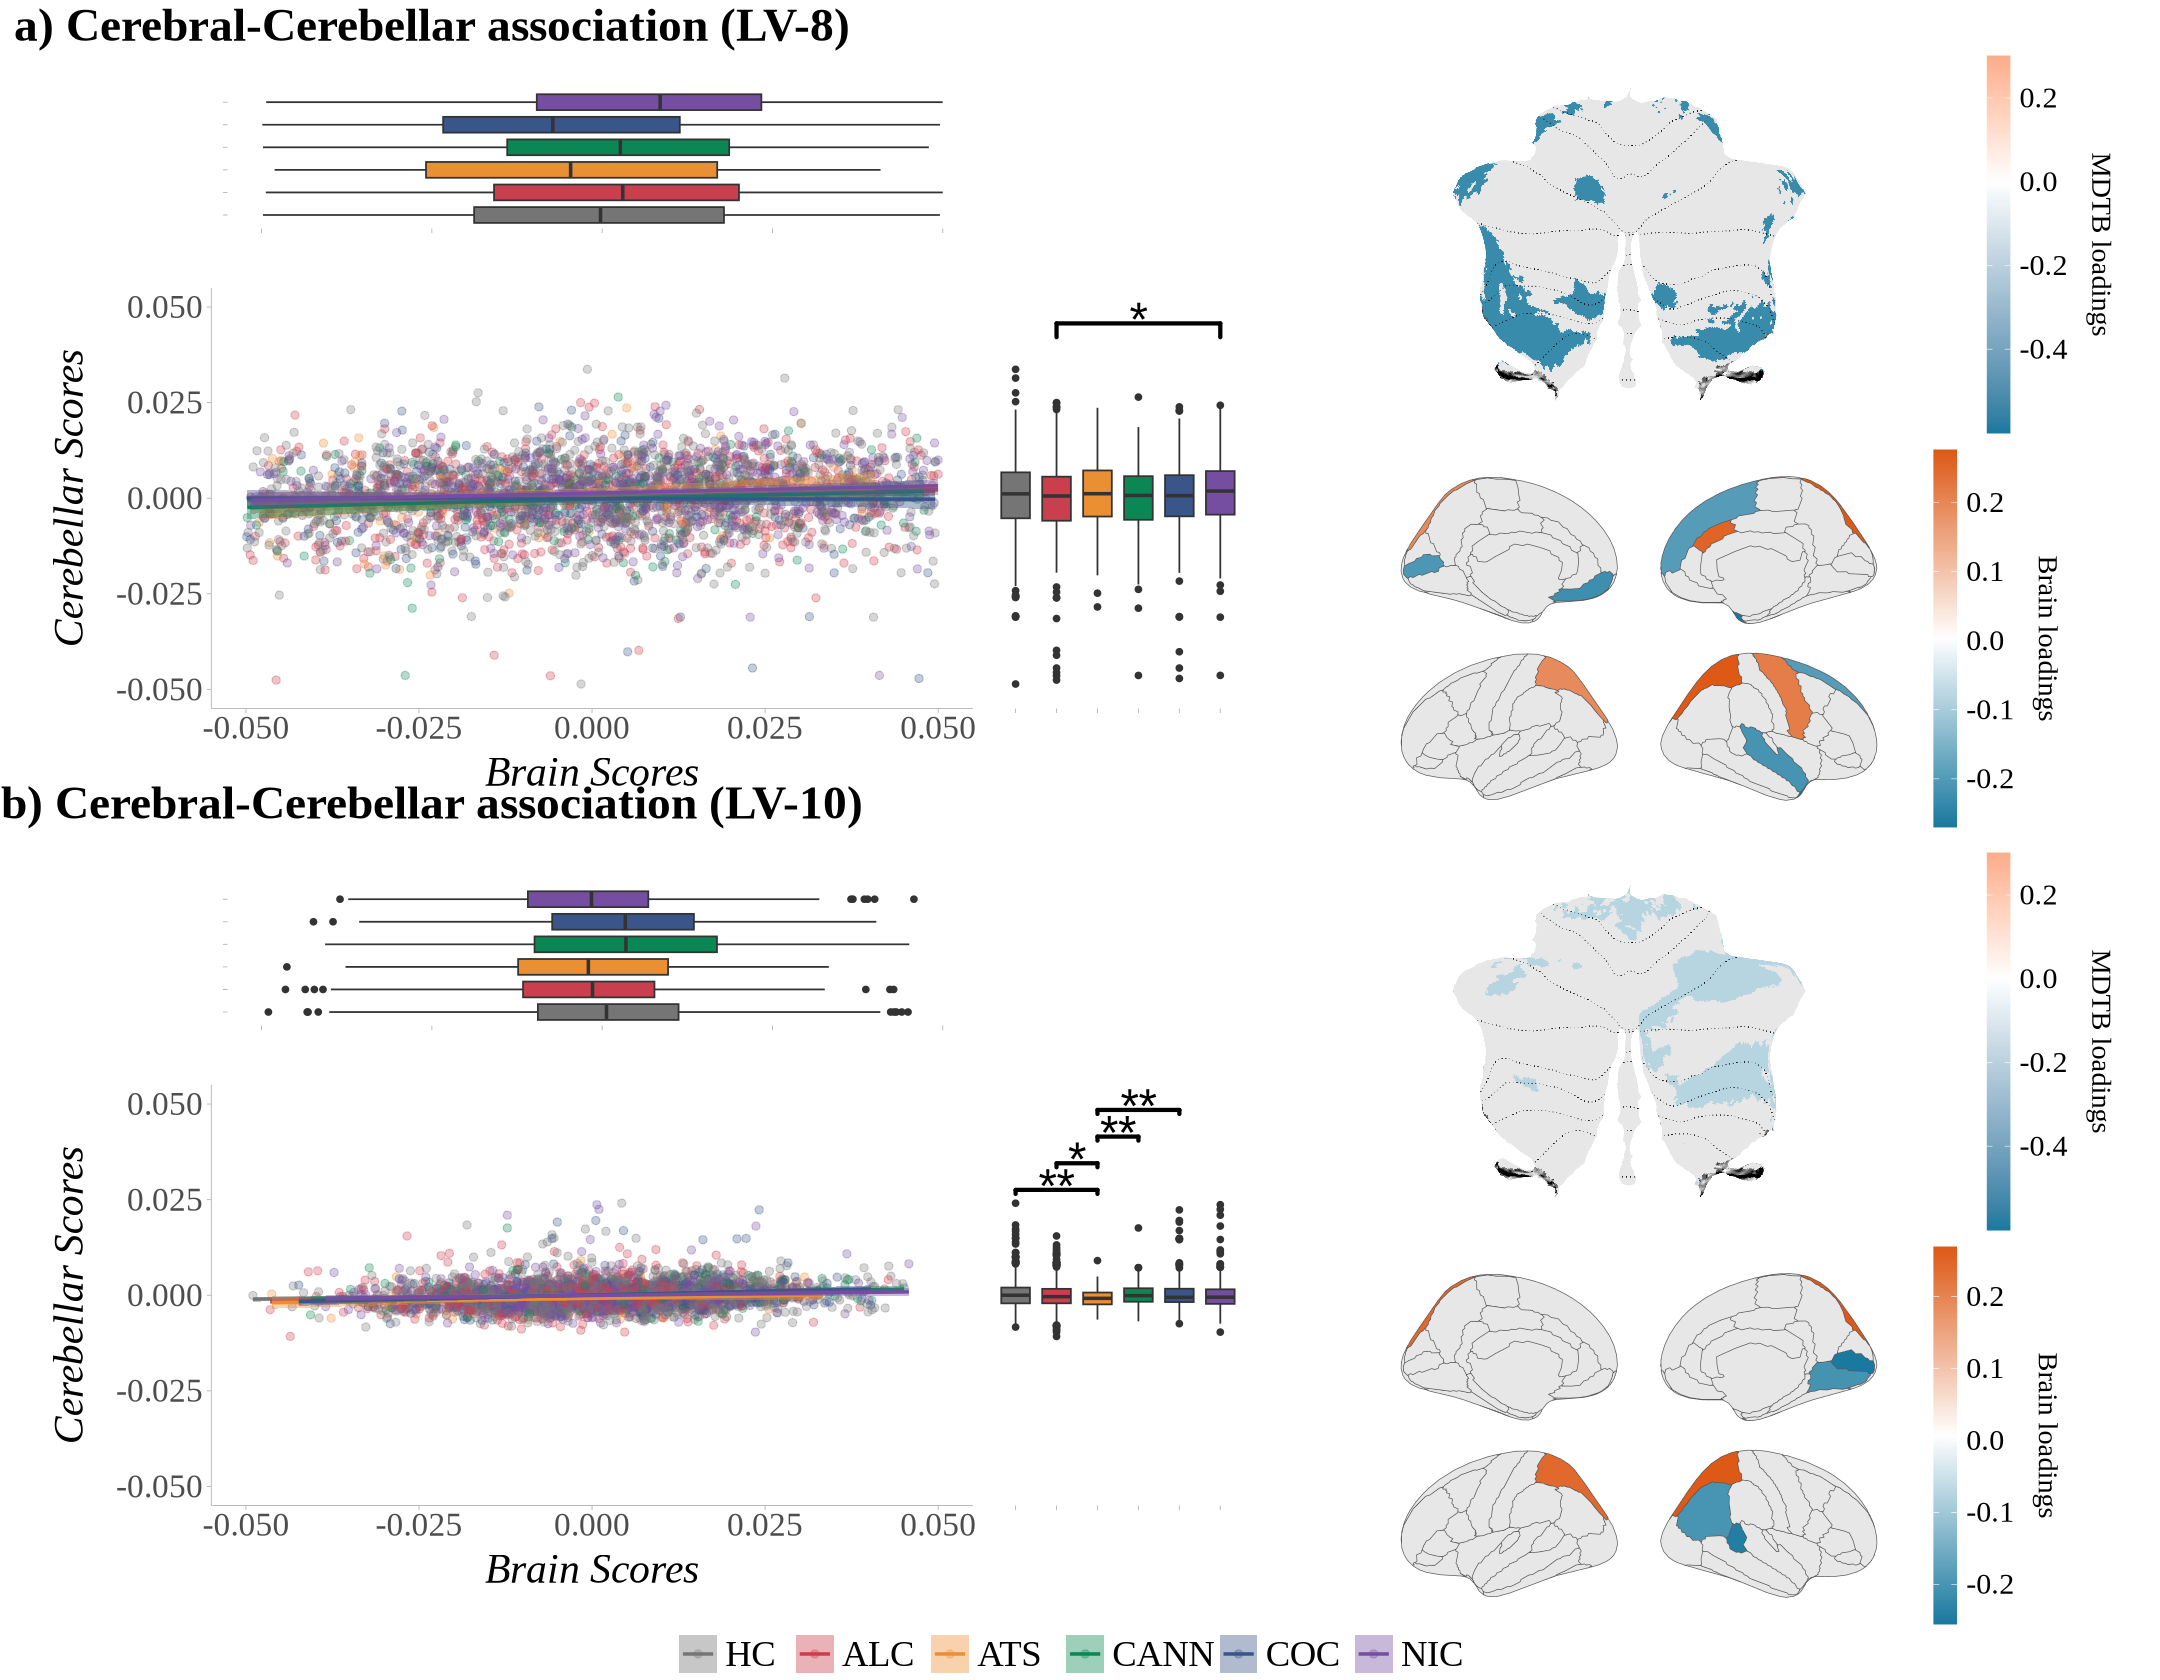

In [46]:
options(repr.plot.width=18, repr.plot.height=14) # to resize plots
Figure_4

## **Saving**

In [ ]:
dir.create("Figures/Supplementaries/", showWarnings = FALSE)
dir.create("Figures/Figures/", showWarnings = FALSE)

### Figures

In [14]:
formats <- c("png", "tiff")
for (fmt in formats) {
    ggsave(filename = paste0("Figures/Figures/Figure_1.", fmt), plot = Figure_1, device = fmt, width = 17, height = 11, units = "in", dpi = 200)
}

# if (!file.exists(paste0("Figures/Figures/Figure_3.png")) && !file.exists(paste0("Figures/Figures/Figure_3.tiff"))) {
#     for (fmt in formats) {
#         ggsave(filename = paste0("Figures/Figures/Figure_3.", fmt), plot = Figure_3, device = fmt, width = 15, height = 11, units = "in", dpi = 300)
#     }
# } else {
#     print("already exported")
# }

if (file.exists("Figures/Figures/Figure_3.svg")) {
    print("already exported")
} else {
    ggsave(
        filename = "Figures/Figures/Figure_3.svg",
        plot = Figure_3,
        device = "svg",
        width = 15,
        height = 15,
        units = "in"
    )
}

# for (fmt in formats) {
#     ggsave(filename = paste0("Figures/Figures/Figure_4.", fmt), plot = Figure_4, device = fmt, width = 18, height = 15, units = "in", dpi = 300)
# }

if (file.exists("Figures/Figures/Figure_4.svg")) {
    print("already exported")
} else {
    ggsave(
        filename = "Figures/Figures/Figure_4.svg",
        plot = Figure_4,
        device = "svg",
        width = 18,
        height = 14,
        units = "in"
    )
}

[1] "already exported"
[1] "already exported"


### Supplementary figures

In [ ]:
# Figure S1
formats <- c("png")
dir.create("Figures/Supplementaries/Figure_S1", showWarnings = FALSE, recursive = TRUE)
for (fmt in formats) {
    out_file <- file.path("Figures", "Supplementaries", "Figure_S1", paste0("Figure_S1.", fmt))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S1, device = fmt, width = 30, height = 18, units = "in", dpi = 300)
    }
}

# Figure S2
dir.create("Figures/Supplementaries/Figure_S2/", showWarnings = FALSE, recursive = TRUE)
iwalk(Acapulco_substances_folds_distribution_plots_all, ~ {
    out_file <- file.path("Figures/Supplementaries/Figure_S2", paste0(.y, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = .x, width = 16, height = 18, dpi = 300)
    }
})

iwalk(MDTB_substances_folds_distribution_plots_all, ~ {
    out_file <- file.path("Figures/Supplementaries/Figure_S2", paste0(.y, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = .x, width = 16, height = 10, dpi = 300)
    }
})

# Figure S3
dir.create("Figures/Supplementaries/Figure_S3", showWarnings = FALSE, recursive = TRUE)
for (i in seq_along(Figure_S3)) {
    out_file <- file.path("Figures/Supplementaries/Figure_S3", paste0("Figure_S3_part", i, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S3[[i]], device = "png",
               width = 13, height = 13, units = "in", dpi = 300)
    }
}

# Figure S4
dir.create("Figures/Supplementaries/Figure_S4", showWarnings = FALSE, recursive = TRUE)
for (i in seq_along(Figure_S4)) {
    out_file <- file.path("Figures", "Supplementaries", "Figure_S4", paste0("Figure_S4_part", i, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S4[[i]], device = "png",
               width = 8, height = 7, units = "in", dpi = 300)
    }
}

# Figure S5
dir.create("Figures/Supplementaries/Figure_S5", showWarnings = FALSE, recursive = TRUE)
for (i in seq_along(Figure_S5)) {
    out_file <- file.path("Figures", "Supplementaries", "Figure_S5", paste0("Figure_S5_part", i, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S5[[i]], device = "png",
               width = 18, height = 15, units = "in", dpi = 300)
    }
}

# Figure S6
dir.create("Figures/Supplementaries/Figure_S6", showWarnings = FALSE, recursive = TRUE)
for (i in seq_along(Figure_S6)) {
    out_file <- file.path("Figures", "Supplementaries", "Figure_S6", paste0("Figure_S6_part", i, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S6[[i]], device = "png",
               width = 15, height = 9, units = "in", dpi = 300)
    }
}

# Figure S7
dir.create("Figures/Supplementaries/Figure_S7", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S7/Figure_S7_users_full.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S7_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S7/Figure_S7_full.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S7, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S8
dir.create("Figures/Supplementaries/Figure_S8", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S8/Figure_S8_users_full.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S8_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S8/Figure_S8_full.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S8, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S9
dir.create("Figures/Supplementaries/Figure_S9", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S9/Figure_S9_users_matchit.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S9_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S9/Figure_S9_matchit.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S9, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S10
dir.create("Figures/Supplementaries/Figure_S10", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S10/Figure_S10_users_matchit.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S10_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S10/Figure_S10_matchit.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S10, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S11
dir.create("Figures/Supplementaries/Figure_S11", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S11/Figure_S11_users_CC.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S11_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S11/Figure_S11_CC.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S11, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S12
dir.create("Figures/Supplementaries/Figure_S12", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S12/Figure_S12_users_CC.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S12_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S12/Figure_S12_CC.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S12, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S13
dir.create("Figures/Supplementaries/Figure_S13", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S13/Figure_S13_users_AI.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S13_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S13/Figure_S13_AI.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S13, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S14
dir.create("Figures/Supplementaries/Figure_S14", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S14/Figure_S14_users_AI.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S14_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S14/Figure_S14_AI.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S14, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S15
dir.create("Figures/Supplementaries/Figure_S15", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S15/Figure_S15_users_CA.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S15_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S15/Figure_S15_CA.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S15, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S16
dir.create("Figures/Supplementaries/Figure_S16", showWarnings = FALSE, recursive = TRUE)
out_file <- "Figures/Supplementaries/Figure_S16/Figure_S16_users_CA.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S16_users, device = "png",
           width = 14, height = 7, units = "in", dpi = 300)
}
out_file <- "Figures/Supplementaries/Figure_S16/Figure_S16_CA.png"
if (!file.exists(out_file)) {
    ggsave(filename = out_file, plot = Figure_S16, device = "png",
           width = 14, height = 16, units = "in", dpi = 300)
}

# Figure S17
dir.create("Figures/Supplementaries/Figure_S17", showWarnings = FALSE, recursive = TRUE)
out_file_acapulco <- "Figures/Supplementaries/Figure_S17/Figure_S17_acapulco.png"
if (!file.exists(out_file_acapulco)) {
    ggsave(filename = out_file_acapulco, plot = Figure_S17[[1]], device = "png",
           width = 13, height = 15, units = "in", dpi = 300)
}
out_file_mdtb <- "Figures/Supplementaries/Figure_S17/Figure_S17_mdtb.png"
if (!file.exists(out_file_mdtb)) {
    ggsave(filename = out_file_mdtb, plot = Figure_S17[[2]], device = "png",
           width = 13, height = 7, units = "in", dpi = 300)
}

# Figure S18
dir.create("Figures/Supplementaries/Figure_S18", showWarnings = FALSE, recursive = TRUE)
for (i in seq_along(Figure_S18)) {
    out_file <- file.path("Figures", "Supplementaries", "Figure_S18", paste0("Figure_S18_part", i, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S18[[i]], device = "png",
               width = 20, height = 30, units = "in", dpi = 300)
    }
}

# Figure S19
dir.create("Figures/Supplementaries/Figure_S19", showWarnings = FALSE, recursive = TRUE)
for (i in seq_along(Figure_S19)) {
    out_file <- file.path("Figures", "Supplementaries", "Figure_S19", paste0("Figure_S19_part", i, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S19[[i]], device = "png",
               width = 27, height = 39, units = "in", dpi = 300)
    }
}

# Figure S20
dir.create("Figures/Supplementaries/Figure_S20", showWarnings = FALSE, recursive = TRUE)
for (i in seq_along(Figure_S20)) {
    out_file <- file.path("Figures", "Supplementaries", "Figure_S20", paste0("Figure_S20_part", i, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S20[[i]], device = "png",
               width = 14, height = 10, units = "in", dpi = 300)
    }
}

# Figure S21
dir.create("Figures/Supplementaries/Figure_S21", showWarnings = FALSE, recursive = TRUE)
for (i in seq_along(Figure_S21)) {
    out_file <- file.path("Figures", "Supplementaries", "Figure_S21", paste0("Figure_S21_part", i, ".png"))
    if (!file.exists(out_file)) {
        ggsave(filename = out_file, plot = Figure_S21[[i]], device = "png",
               width = 26, height = 38, units = "in", dpi = 300)
    }
}

---
## **Sanity Check Supplementary Figures (S22 – S26)**



In [33]:

# ── Load sanity-check outputs ──────────────────────────────────────────────────
within_site_df  <- read_csv("Statistics/Sanity_check/within_site_User_vs_HC.csv",
                            show_col_types = FALSE)
loso_df         <- read_csv("Statistics/Sanity_check/LOSO_effect_sizes.csv",
                            show_col_types = FALSE)
loso_summary_df <- read_csv("Statistics/Sanity_check/LOSO_summary_TotalCerVol.csv",
                            show_col_types = FALSE)
missingness_df  <- read_csv("Statistics/Sanity_check/missingness_by_site_group.csv",
                            show_col_types = FALSE)

# CC / AI model results (loaded only if not already in session)
if (!exists("p_values_Acapulco_CC_user_vs_control")) {
    load("Statistics/Sanity_check/Acapulco/Acapulco_sanity_check_statistics.RData")
}


### **Figure S22** — Site × Substance sample overlap heatmap

In [34]:

site_overlap_long_S18 <- Volumes_Cerebellum_Acapulco_Harmonized %>%
    mutate(
        Substance_label = case_when(
            Control != 0 ~ as.character(Substance),
            Control == 0 ~ "HC"
        ),
        Substance_label = factor(
            Substance_label,
            levels = c("ALC", "ATS", "CANN", "COC", "NIC", "HC")
        )
    ) %>%
    filter(!is.na(Substance_label), Substance_label != "OPI") %>%
    count(Database, Substance_label)

Figure_S22 <- site_overlap_long_S18 %>%
    ggplot(aes(
        x    = Substance_label,
        y    = fct_reorder(Database, n, .fun = sum, .desc = TRUE),
        fill = n
    )) +
    geom_tile(color = "white", linewidth = 0.6) +
    geom_text(aes(label = n), size = 5, family = "Times New Roman") +
    scale_fill_gradient(
        low  = "#f0f0f0",
        high = "#3A5589",
        name = "n subjects"
    ) +
    scale_x_discrete(expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    labs(x = "Substance group", y = "Scanner site") +
    theme_bw(base_size = 14) +
    theme_output +
    theme(
        axis.text.x  = element_text(size = 20, angle = 45, hjust = 1),
        axis.text.y  = element_text(size = 16),
        panel.grid   = element_blank(),
        legend.text  = element_text(size = 18),
        legend.title = element_text(size = 20)
    )


### **Figure S23** — Within-site case-control forest plot (Total Cerebellar Volume)

In [35]:

# Pooled Cohen's d reference line (all eligible sites combined)
m_overall_S19  <- lm(Total_Cerebel_Vol ~ relevel(group, ref = "HC"),
                     data = Acapulco_volumes)
overall_d_S19  <- coef(m_overall_S19)[2] / sigma(m_overall_S19)

# Forest plot — each row = one site, x = standardised effect size
Figure_S23 <- within_site_df %>%
    filter(region == "Total_Cerebel_Vol") %>%
    mutate(
        d_low    = conf.low  / sigma,
        d_high   = conf.high / sigma,
        Database = fct_reorder(Database, effect.size)
    ) %>%
    ggplot(aes(x = effect.size, y = Database)) +
    geom_vline(xintercept = 0,
               color = "grey70", linewidth = 0.5) +
    geom_vline(xintercept = overall_d_S19,
               color = "#3A5589", linetype = "dashed", linewidth = 0.9) +
    geom_errorbarh(aes(xmin = d_low, xmax = d_high),
                   height = 0.35, color = "grey50", linewidth = 0.7) +
    geom_point(aes(size = n_user + n_hc), color = "#C93F4D", alpha = 0.85) +
    scale_size_continuous(name = "n (User + HC)", range = c(2, 9)) +
    labs(
        x = "Cohen's d (within-site)",
        y = "Scanner site"
    ) +
    theme_bw(base_size = 14) +
    theme_output +
    theme(
        axis.text.x  = element_text(size = 20),
        axis.text.y  = element_text(size = 16),
        legend.text  = element_text(size = 18),
        legend.title = element_text(size = 20)
    )

### **Figure S24** — Leave-one-site-out (LOSO) effect sizes per substance (Total Cerebellar Volume)

In [36]:

Figure_S24 <- loso_df %>%
    filter(region == "Total_Cerebel_Vol") %>%
    left_join(
        loso_summary_df %>% select(substance, effect_size_overall),
        by = "substance"
    ) %>%
    mutate(substance = factor(substance, levels = c("ALC","ATS","CANN","COC","NIC"))) %>%
    ggplot(aes(x = effect.size,
               y = fct_reorder(site_removed, effect.size,
                               .fun = median, .desc = FALSE))) +
    geom_vline(xintercept = 0,
               color = "grey70", linewidth = 0.5) +
    geom_vline(aes(xintercept = effect_size_overall),
               color = "#3A5589", linetype = "dashed", linewidth = 0.9) +
    geom_point(aes(size = n_user + n_hc, color = substance), alpha = 0.85) +
    scale_color_manual(values = pal_substances, guide = "none") +
    scale_size_continuous(name = "n (User + HC)", range = c(2, 7)) +
    facet_wrap(~substance, scales = "free_y", ncol = 3) +
    labs(
        x = "Cohen's d (LOSO)",
        y = "Site removed"
    ) +
    theme_bw(base_size = 13) +
    theme_output +
    theme(legend.position  = "bottom",
        strip.text       = element_text(face = "bold", size = 22),
        strip.background = element_rect(fill = "grey95"),
        axis.text.x      = element_text(size = 18),
        axis.text.y      = element_text(size = 13),
        legend.text      = element_text(size = 18),
        legend.title     = element_text(size = 20)
    )

### **Figure S25** — Missingness map: % missing Age and Sex by site × diagnostic group

In [37]:

Figure_S25 <- missingness_df %>%
    filter(Substance_label %in% c("ALC","ATS","CANN","COC","NIC","HC")) %>%
    mutate(Substance_label = factor(Substance_label,
                                    levels = c("ALC","ATS","CANN","COC","NIC","HC"))) %>%
    pivot_longer(
        cols      = c(pct_missing_Age, pct_missing_Sex),
        names_to  = "variable",
        values_to = "pct_missing"
    ) %>%
    mutate(variable = recode(variable,
                             pct_missing_Age = "Age",
                             pct_missing_Sex = "Sex")) %>%
    ggplot(aes(
        x    = Substance_label,
        y    = fct_reorder(Database, pct_missing, .fun = mean, .desc = TRUE),
        fill = pct_missing
    )) +
    geom_tile(color = "white", linewidth = 0.5) +
    geom_text(
        aes(label = paste0(pct_missing, "%")),
        size   = 4.5,
        family = "Times New Roman"
    ) +
    scale_fill_gradient(
        low    = "#f7f7f7",
        high   = "#08306b",
        name   = "% missing",
        limits = c(0, 100)
    ) +
    facet_wrap(~variable) +
    scale_x_discrete(expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    labs(x = "Diagnostic group", y = "Scanner site") +
    theme_bw(base_size = 13) +
    theme_output +
    theme(
        strip.text       = element_text(face = "bold", size = 22),
        strip.background = element_rect(fill = "grey95"),
        axis.text.x      = element_text(size = 20, angle = 45, hjust = 1),
        axis.text.y      = element_text(size = 14),
        panel.grid       = element_blank(),
        legend.text      = element_text(size = 18),
        legend.title     = element_text(size = 20)
    )


### **Figure S26** — Imputation sensitivity: Primary vs Complete-Cases vs Alternative-Imputation

In [38]:

# ── Imputation sensitivity scatter: match ID vs CC vs AI ────────────────────────

# Helper: build one scatter panel
make_sens_panel <- function(sens_df, y_col, y_lab) {
    sens_df %>%
        ggplot(aes(
            x     = d_matchit,
            y     = .data[[y_col]],
            color = sig_matchit,
            label = region
        )) +
        geom_hline(yintercept = 0, color = "grey80", linewidth = 0.4) +
        geom_vline(xintercept = 0, color = "grey80", linewidth = 0.4) +
        geom_abline(slope = 1, intercept = 0,
                    linetype = "dashed", color = "grey50", linewidth = 0.7) +
        geom_point(size = 3.5, alpha = 0.80) +
        scale_color_manual(
            values = c("TRUE" = "#C93F4D", "FALSE" = "#757575"),
            name   = "FDR < 0.05\n(Matched sample)",
            labels = c("No", "Yes")
        ) +
        labs(
            x = "Cohen's d — Matched sample",
            y = paste0("Cohen's d — ", y_lab)
        ) +
        theme_bw(base_size = 13) +
        theme_output +
        theme(
            axis.text    = element_text(size = 18),
            legend.text  = element_text(size = 18),
            legend.title = element_text(size = 20)
        )
}

# ── User vs HC ─────────────────────────────────────────────────────────────────
sens_user <- Acapulco_substance_merged_full_folds_matchit %>%
    select(region, effect.size_matchit, p_adj_matchit, significant_all) %>%
    rename(d_matchit = effect.size_matchit, padj_matchit = p_adj_matchit) %>%
    left_join(
        p_values_Acapulco_CC_user_vs_control %>%
            select(region, effect.size, p.adj) %>%
            rename(d_CC = effect.size, padj_CC = p.adj),
        by = "region"
    ) %>%
    left_join(
        p_values_Acapulco_AI_user_vs_control %>%
            select(region, effect.size, p.adj) %>%
            rename(d_AI = effect.size, padj_AI = p.adj),
        by = "region"
    ) %>%
    mutate(sig_matchit = !is.na(padj_matchit) & padj_matchit < 0.05 & significant_all == TRUE)

# ── Substance vs HC ────────────────────────────────────────────────────────────
sens_substance <- Acapulco_substance_merged_full_folds_matchit %>%
    select(Substance, region, effect.size_matchit, p_adj_matchit, significant_all) %>%
    rename(d_matchit = effect.size_matchit, padj_matchit = p_adj_matchit) %>%
    left_join(
        p_values_Acapulco_CC_substance_vs_control %>%
            select(Substance, region, effect.size, p.adj) %>%
            rename(d_CC = effect.size, padj_CC = p.adj),
        by = c("Substance", "region")
    ) %>%
    left_join(
        p_values_Acapulco_AI_substance_vs_control %>%
            select(Substance, region, effect.size, p.adj) %>%
            rename(d_AI = effect.size, padj_AI = p.adj),
        by = c("Substance", "region")
    ) %>%
    mutate(
        sig_matchit = !is.na(padj_matchit) & padj_matchit < 0.05,
        Substance   = factor(Substance, levels = c("ALC","ATS","CANN","COC","NIC"))
    )

# # ── User vs HC panels ─────────────────────────────────────────────────────────
p_user_cc <- make_sens_panel(sens_user, "d_CC",
                             "Complete Cases (CC)") + ggtitle("User vs HC")
p_user_ai <- make_sens_panel(sens_user, "d_AI",
                             "Alternative Imputation (AI)") + ggtitle("User vs HC")

Figure_S26_user <- (p_user_cc | p_user_ai) +
    plot_layout(guides = "collect") +
    plot_annotation(
        tag_levels = "a", tag_suffix = ")",
        theme = theme(
            plot.tag = element_text(
                face = "bold", family = "Times New Roman", size = 32
            )
        )
    )

# ── Substance vs HC panels (faceted by substance) ─────────────────────────────
Figure_S26_substance <- sens_substance %>%
    pivot_longer(
        cols      = c(d_CC, d_AI),
        names_to  = "sensitivity",
        values_to = "d_sens"
    ) %>%
    mutate(sensitivity = recode(sensitivity,
                                d_CC = "Complete Cases (CC)",
                                d_AI = "Alternative Imputation (AI)")) %>%
    ggplot(aes(x = d_matchit, y = d_sens, color = sig_matchit)) +
    geom_hline(yintercept = 0, color = "grey80", linewidth = 0.4) +
    geom_vline(xintercept = 0, color = "grey80", linewidth = 0.4) +
    geom_abline(slope = 1, intercept = 0,
                linetype = "dashed", color = "grey50", linewidth = 0.7) +
    geom_point(size = 2.5, alpha = 0.75) +
    scale_color_manual(
        values = c("TRUE" = "#C93F4D", "FALSE" = "#757575"),
        name   = "FDR < 0.05\n(Matched sample)",
        labels = c("No", "Yes")
    ) +
    facet_grid(sensitivity ~ Substance) +
    labs(
        x = "Cohen's d — Matched sample",
        y = "Cohen's d"
    ) +
    theme_bw(base_size = 12) +
    theme_output +
    theme(
        strip.text       = element_text(face = "bold", size = 16),
        strip.background = element_rect(fill = "grey95"),
        axis.text        = element_text(size = 14),
        legend.text      = element_text(size = 16),
        legend.title     = element_text(size = 18)
    )

Figure_S26 <- list(
    user      = Figure_S26_user,
    substance = Figure_S26_substance
)


### Export — Figures S22 – S26

In [39]:

# ── Export sanity-check supplementary figures (S22 – S25) ─────────────────────
sc_supp_dir <- file.path("Figures", "Supplementaries")

# Figure S22 — site × substance heatmap
dir.create(file.path(sc_supp_dir, "Figure_S22"), showWarnings = FALSE, recursive = TRUE)
out_S22 <- file.path(sc_supp_dir, "Figure_S22", "Figure_S22.png")
if (!file.exists(out_S22)) {
    ggsave(filename = out_S22, plot = Figure_S22, device = "png",
           width = 10, height = 16, units = "in", dpi = 300)
}

# Figure S23 — within-site forest plot
dir.create(file.path(sc_supp_dir, "Figure_S23"), showWarnings = FALSE, recursive = TRUE)
out_S23 <- file.path(sc_supp_dir, "Figure_S23", "Figure_S23.png")
if (!file.exists(out_S23)) {
    ggsave(filename = out_S23, plot = Figure_S23, device = "png",
           width = 10, height = 13, units = "in", dpi = 300)
}

# Figure S24 — LOSO per substance
dir.create(file.path(sc_supp_dir, "Figure_S24"), showWarnings = FALSE, recursive = TRUE)
out_S24 <- file.path(sc_supp_dir, "Figure_S24", "Figure_S24.png")
if (!file.exists(out_S24)) {
    ggsave(filename = out_S24, plot = Figure_S24, device = "png",
           width = 16, height = 17, units = "in", dpi = 300)
}

# Figure S25 — missingness heatmap
dir.create(file.path(sc_supp_dir, "Figure_S25"), showWarnings = FALSE, recursive = TRUE)
out_S25 <- file.path(sc_supp_dir, "Figure_S25", "Figure_S25.png")
if (!file.exists(out_S25)) {
    ggsave(filename = out_S25, plot = Figure_S25, device = "png",
           width = 15, height = 11, units = "in", dpi = 300)
}

# Figure S26 — imputation sensitivity scatter (two panels: user + substance)
dir.create(file.path(sc_supp_dir, "Figure_S26"), showWarnings = FALSE, recursive = TRUE)
out_S26_user <- file.path(sc_supp_dir, "Figure_S26", "Figure_S26a_user.png")
if (!file.exists(out_S26_user)) {
    ggsave(filename = out_S26_user, plot = Figure_S26$user, device = "png",
           width = 16, height = 6, units = "in", dpi = 300)
}
out_S26_sub <- file.path(sc_supp_dir, "Figure_S26", "Figure_S26b_substance.png")
if (!file.exists(out_S26_sub)) {
    ggsave(filename = out_S26_sub, plot = Figure_S26$substance, device = "png",
           width = 15, height = 8, units = "in", dpi = 300)
}

`height` was translated to `width`.
